# Stroke Generation Model

In [1]:
import os
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.signal import find_peaks
from scipy.special import erf
from typing import Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical, MultivariateNormal
from torch.utils.data import Dataset, DataLoader

sys.path.append(os.path.join(os.getcwd(), ".."))
from framework import Curve, Stroke, StrokeSequence
from framework.Spatial.BezierOptimization import BezierOptimization

## Stroke

In [2]:
STROKE_TIME_COLS = ['mu', 'sigma', 't0']
STROKE_GEOM_COLS = ['delta_p', 'u_e', 'lambda_e', 'u_s', 'lambda_s']
ARRAY_COLS = ['delta_p', 'u_s', 'u_e']
DATABASE_ROOT = os.getcwd().split('src')[0] + 'reconstructed_csv'


# ---- network I/O definition ----
# Outputs of the stroke network. Every stroke is expressed from its own origin: it starts at zero.
# Timing: dt0 is the interval between the onset of the stroke and the onset of the previous one (0 for the
# first stroke), so the absolute time origin of the recording never enters the network.
# The start tangent u_s is not an output: it is the end tangent of the previous stroke (G1 junction)
# and, for the first stroke, the direction of its chord delta_p.
TARGET_KEYS = ["dt0", "mu", "sigma", "lambda_s", "lambda_e", "u_e", "delta_p"]
KEY_DIMS = {"dt0": 1, "mu": 1, "sigma": 1, "lambda_s": 1, "lambda_e": 1, "u_e": 3, "delta_p": 3}
# Previous-stroke input = every target EXCEPT delta_p (a stroke never knows where the previous one ended).
PREV_KEYS = [f"prev_{k}" for k in TARGET_KEYS if k != "delta_p"]

GEOM_SHARED_KEYS = ("wp", "wp_n", "delta_p")        # same zero-mean isotropic scale (see compute_stats)
STAT_KEYS = ["wp", "wp_n"] + TARGET_KEYS
DATASET_KEYS = ["wp", "wp_n", "is_first"] + TARGET_KEYS + PREV_KEYS

## Nework Architecture

### Mixture Density Network Head

In [3]:

class MixtureDensityNetwork(nn.Module):
    """
    MDN head with full-covariance Gaussian components.
    Outputs: means [B, K, D], lower Cholesky factors [B, K, D, D], mixing logits [B, K].
    """

    def __init__(self, input_dim, output_dim, num_components, hidden_dim=128, min_diag=1e-3):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.num_components = num_components
        self.hidden_dim = hidden_dim
        self.min_diag = min_diag
        self.num_tril = output_dim * (output_dim + 1) // 2

        rows, cols = torch.tril_indices(output_dim, output_dim)
        self.register_buffer("tril_rows", rows, persistent=False)
        self.register_buffer("tril_cols", cols, persistent=False)
        self.register_buffer("diag_mask", rows == cols, persistent=False)

        self.hidden_layer = nn.Linear(input_dim, hidden_dim)
        self.weights_layer = nn.Linear(hidden_dim, num_components)  # mixing logits
        self.means_layer = nn.Linear(hidden_dim, num_components * output_dim)
        self.scale_layer = nn.Linear(hidden_dim, num_components * self.num_tril)

    def set_weights(self, target_samples: torch.Tensor, sigma_weight_scale: float = 0.1):
        """
        Initialization. `target_samples` [N, D] should already be standardized.
        Means are spread over the target range; each Cholesky factor starts as
        diag(std_d) with zero off-diagonal entries.
        """
        nn.init.kaiming_uniform_(self.hidden_layer.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden_layer.bias)

        nn.init.xavier_uniform_(self.weights_layer.weight)
        nn.init.xavier_uniform_(self.means_layer.weight)
        nn.init.xavier_uniform_(self.scale_layer.weight)

        t_min = target_samples.min(dim=0).values  # [D]
        t_max = target_samples.max(dim=0).values  # [D]
        mean_bias = torch.empty(self.num_components, self.output_dim)
        for k in range(self.num_components):
            mean_bias[k] = (t_min + (t_max - t_min) * (k + 0.5) / self.num_components).cpu()

        with torch.no_grad():
            self.means_layer.bias.copy_(mean_bias.reshape(-1))
            self.scale_layer.weight.mul_(sigma_weight_scale)

            # inverse softplus so that diag(L) starts at the per-dimension data std
            data_std = target_samples.std(dim=0).to(self.scale_layer.bias)
            init_diag = (data_std - self.min_diag).clamp_min(1e-3)
            raw_diag = torch.log(torch.expm1(init_diag))
            bias = torch.zeros(self.num_components, self.num_tril).to(self.scale_layer.bias)
            bias[:, self.diag_mask] = raw_diag
            self.scale_layer.bias.copy_(bias.reshape(-1))

    def _build_scale_tril(self, raw: torch.Tensor) -> torch.Tensor:
        """raw [B, K, m] -> lower-triangular L [B, K, D, D] with positive diagonal."""
        batch = raw.size(0)
        dim = self.output_dim
        tril = raw.new_zeros(batch, self.num_components, dim, dim)
        tril[..., self.tril_rows, self.tril_cols] = raw
        diag = F.softplus(tril.diagonal(dim1=-2, dim2=-1)) + self.min_diag
        return tril.tril(-1) + torch.diag_embed(diag)

    def forward(self, x: torch.Tensor):
        hidden = torch.relu(self.hidden_layer(x))
        mix_logits = self.weights_layer(hidden)
        means = self.means_layer(hidden).view(-1, self.num_components, self.output_dim)
        raw = self.scale_layer(hidden).view(-1, self.num_components, self.num_tril)
        return means, self._build_scale_tril(raw), mix_logits

### Full Model Architecture

In [4]:
class GenerativeModel(nn.Module):
    """Generative model of strokes: embeddings -> LSTM -> trunk -> full-covariance MDN."""

    def __init__(self, input_dim, embedding_dim, LSTM_dim, LSTM_count, output_dim,
                 mixture_components, recur_dim=None, min_diag=1e-3, mdn_hidden_dim=128):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.embedding_dim = embedding_dim
        self.lstm_dim = LSTM_dim
        self.lstm_count = LSTM_count
        self.mixture_components = mixture_components
        # dimension of the previous-step vector (defaults to the target dimension)
        self.recur_dim = output_dim if recur_dim is None else recur_dim

        self.input_embedding = nn.Linear(input_dim, embedding_dim)
        self.recur_embedding = nn.Linear(self.recur_dim, embedding_dim)
        self.lstm = nn.LSTM(input_size=embedding_dim * 2, hidden_size=LSTM_dim,
                            num_layers=LSTM_count, batch_first=True)
        self.trunk = nn.Linear(LSTM_dim, LSTM_dim)
        self.mdn = MixtureDensityNetwork(LSTM_dim, output_dim, num_components=mixture_components,
                                         hidden_dim=mdn_hidden_dim, min_diag=min_diag)

    def set_weights(self, target_samples, sigma_weight_scale=0.1):
        self.mdn.set_weights(target_samples, sigma_weight_scale)
        for layer in (self.input_embedding, self.recur_embedding, self.trunk):
            nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)

    def forward(self, x, prev_output=None, state=None, return_state=False):
        """
        Args:
            x: conditioning input [B, input_dim]
            prev_output: previous-step vector [B, recur_dim] (zeros embedding if None)
            state: optional LSTM state (h, c) carried across calls; None resets it
        Returns:
            means [B, K, D], scale_tril [B, K, D, D], mix_logits [B, K] (+ state if requested)
        """
        input_embedded = self.input_embedding(x)
        if prev_output is not None:
            prev_embedded = self.recur_embedding(prev_output)
        else:
            prev_embedded = torch.zeros_like(input_embedded)

        combined = torch.cat((input_embedded, prev_embedded), dim=-1)
        lstm_out, new_state = self.lstm(combined.unsqueeze(1), state)  # sequence length 1
        trunk_out = torch.relu(self.trunk(lstm_out.squeeze(1)))

        means, scale_tril, mix_logits = self.mdn(trunk_out)
        if return_state:
            return means, scale_tril, mix_logits, new_state
        return means, scale_tril, mix_logits

    @torch.no_grad()
    def sample(self, x, prev_output=None, state=None):
        means, scale_tril, mix_logits = self.forward(x, prev_output, state)
        batch_idx = torch.arange(means.size(0), device=means.device)
        comp_idx = Categorical(logits=mix_logits).sample()
        sel_mean = means[batch_idx, comp_idx]          # [B, D]
        sel_tril = scale_tril[batch_idx, comp_idx]     # [B, D, D]
        eps = torch.randn_like(sel_mean)
        return sel_mean + (sel_tril @ eps.unsqueeze(-1)).squeeze(-1)

## Loss

In [5]:
def duplication_matrix(dim: int, device=None, dtype=None) -> torch.Tensor:
    """
    Duplication matrix Dup such that vec(S) = Dup @ vech(S) for any symmetric S.
    Shape: [dim * dim, dim * (dim + 1) // 2]. Row-major vec, lower-triangle vech.
    """
    rows, cols = torch.tril_indices(dim, dim, device=device)
    n_free = rows.numel()
    dup = torch.zeros(dim * dim, n_free, device=device, dtype=dtype)
    col_idx = torch.arange(n_free, device=device)
    dup[rows * dim + cols, col_idx] = 1.0
    dup[cols * dim + rows, col_idx] = 1.0
    return dup


def gaussian_fisher(sigma: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Explicit Fisher information blocks of N(mu, Sigma).

    Args:
        sigma: covariance matrices, shape [..., D, D].
    Returns:
        fisher_mu:    [..., D, D]   = Sigma^-1
        fisher_sigma: [..., m, m]   = 1/2 Dup^T (Sigma^-1 (x) Sigma^-1) Dup, m = D(D+1)/2
    """
    dim = sigma.size(-1)
    dup = duplication_matrix(dim, sigma.device, sigma.dtype)
    sigma_inv = torch.linalg.inv(sigma)
    kron = torch.einsum("...ij,...kl->...ikjl", sigma_inv, sigma_inv)
    kron = kron.reshape(*sigma.shape[:-2], dim * dim, dim * dim)
    fisher_sigma = 0.5 * dup.T @ kron @ dup
    return sigma_inv, fisher_sigma


def gaussian_fisher_matrix(sigma: torch.Tensor) -> torch.Tensor:
    """Full block-diagonal Fisher matrix over (mu, vech(Sigma)), shape [..., D+m, D+m]."""
    fisher_mu, fisher_sigma = gaussian_fisher(sigma)
    dim, n_free = fisher_mu.size(-1), fisher_sigma.size(-1)
    full = sigma.new_zeros(*sigma.shape[:-2], dim + n_free, dim + n_free)
    full[..., :dim, :dim] = fisher_mu
    full[..., dim:, dim:] = fisher_sigma
    return full


def gaussian_natural_gradient(
    diff: torch.Tensor,
    sigma: torch.Tensor,
    resp: torch.Tensor,
    explicit_fisher: bool = False,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Complete-data natural gradient of resp * log N(y; mu, Sigma) w.r.t. (mu, vech(Sigma)).

    Args:
        diff:  y - mu, shape [..., D]
        sigma: covariance, shape [..., D, D]
        resp:  responsibilities, shape [...]
        explicit_fisher: if True, build the Fisher blocks explicitly and solve F x = grad
            (O(D^6) per component: use it to validate, not for training).
            If False, use the equivalent closed form.
    Returns:
        nat_mu:    [..., D]
        nat_sigma: [..., m]  (vech coordinates)
    """
    dim = diff.size(-1)
    rows, cols = torch.tril_indices(dim, dim, device=diff.device)
    outer = diff.unsqueeze(-1) * diff.unsqueeze(-2)  # d d^T

    if not explicit_fisher:
        nat_mu = resp.unsqueeze(-1) * diff
        nat_sigma = resp[..., None, None] * (outer - sigma)
        return nat_mu, nat_sigma[..., rows, cols]

    fisher_mu, fisher_sigma = gaussian_fisher(sigma)
    sigma_inv = fisher_mu
    dup = duplication_matrix(dim, diff.device, diff.dtype)

    grad_mu = resp.unsqueeze(-1) * (sigma_inv @ diff.unsqueeze(-1)).squeeze(-1)
    # symmetric matrix derivative of resp * log N w.r.t. Sigma
    grad_mat = 0.5 * resp[..., None, None] * (sigma_inv @ outer @ sigma_inv - sigma_inv)
    grad_vech = torch.einsum("pm,...p->...m", dup, grad_mat.reshape(*sigma.shape[:-2], dim * dim))

    nat_mu = torch.linalg.solve(fisher_mu, grad_mu.unsqueeze(-1)).squeeze(-1)
    nat_sigma = torch.linalg.solve(fisher_sigma, grad_vech.unsqueeze(-1)).squeeze(-1)
    return nat_mu, nat_sigma


def categorical_natural_gradient(
    resp: torch.Tensor, pi: torch.Tensor, pi_floor: float = 1e-4
) -> torch.Tensor:
    """
    Natural gradient of sum_k r_k log pi_k w.r.t. the softmax logits.
    The Fisher matrix diag(pi) - pi pi^T is singular; r / pi solves F x = r - pi, and the
    mean is removed (softmax is invariant to a constant shift of the logits).
    `pi_floor` avoids huge steps when a component has a vanishing weight.
    """
    ratio = resp / pi.clamp_min(pi_floor)
    return ratio - ratio.mean(dim=-1, keepdim=True)

In [6]:
def model_io(batch, device):
    """Normalized batch -> (conditioning x, previous-stroke input, target)."""
    x = torch.cat([batch["wp"], batch["wp_n"], batch["is_first"]], dim=-1).to(device)
    prev = torch.cat([batch[k] for k in PREV_KEYS], dim=-1).to(device)
    target = torch.cat([batch[k] for k in TARGET_KEYS], dim=-1).to(device)
    return x, prev, target


def mixture_nll(means, scale_tril, logits, target):
    """Mean negative log-likelihood of `target` [B, D] under the mixture (means [B,K,D], L [B,K,D,D], logits [B,K])."""
    log_prob = MultivariateNormal(means, scale_tril=scale_tril).log_prob(target.unsqueeze(1))
    return -torch.logsumexp(F.log_softmax(logits, dim=-1) + log_prob, dim=-1).mean()


def mdn_nll_loss(model, batch, device, return_nll=True, **_):
    """Plain mixture NLL (same call signature as ngem_loss)."""
    x, prev, target = model_io(batch, device)
    means, scale_tril, logits = model(x, prev_output=prev)
    nll = mixture_nll(means, scale_tril, logits, target)
    return nll, nll.detach()

In [7]:
def ngem_loss(
    model,
    batch,
    device,
    fisher_mode: str = "closed_form",
    natural_mixing: bool = True,
    pi_floor: float = 1e-4,
    return_nll: bool = False,
):
    """
    Multivariate (full covariance) nGEM surrogate loss.

    E-step: responsibilities from the current parameters (no gradient).
    M-step: the complete-data natural gradient w.r.t. the network outputs
            (means, vech(Sigma), mixing logits) is computed with the Fisher blocks of
            each component and injected into backprop through a surrogate loss, so that
            d(loss)/d(output) = -natural_gradient / batch_size.

    Args:
        fisher_mode: "closed_form" (fast) or "explicit" (builds and solves the Fisher
            blocks; use it for validation).
        natural_mixing: natural gradient for the mixing logits (True) or plain gradient
            r - pi (False).
        pi_floor: lower clamp on pi in the categorical natural gradient.
        return_nll: also return the mixture NLL (detached) for monitoring.
    """
    if fisher_mode not in ("closed_form", "explicit"):
        raise ValueError("fisher_mode must be 'closed_form' or 'explicit'")

    input_data, prev_input, target = model_io(batch, device)
    means, scale_tril, mix_logits = model(input_data, prev_output=prev_input)
    batch_size, dim = target.shape

    # ---- E-step (no gradient) ----
    with torch.no_grad():
        dist = MultivariateNormal(loc=means.detach(), scale_tril=scale_tril.detach())
        log_prob = dist.log_prob(target.unsqueeze(1))                  # [B, K]
        log_joint = F.log_softmax(mix_logits.detach(), dim=-1) + log_prob
        resp = torch.softmax(log_joint, dim=-1)                        # [B, K]
        nll = -torch.logsumexp(log_joint, dim=-1).mean()
        pi = torch.softmax(mix_logits.detach(), dim=-1)

    # ---- M-step: natural gradients w.r.t. the network outputs ----
    diff = (target.unsqueeze(1) - means).detach()                      # [B, K, D]
    cov = scale_tril @ scale_tril.transpose(-1, -2)                    # Sigma = L L^T (with grad)
    rows, cols = torch.tril_indices(dim, dim, device=target.device)
    cov_vech = cov[..., rows, cols]                                    # [B, K, m]

    nat_mu, nat_cov = gaussian_natural_gradient(
        diff, cov.detach(), resp, explicit_fisher=(fisher_mode == "explicit")
    )
    nat_pi = categorical_natural_gradient(resp, pi, pi_floor) if natural_mixing else resp - pi

    # Surrogate: its gradient w.r.t. (means, vech(Sigma), logits) is minus the natural
    # gradient; autograd then applies the Jacobian (chain rule) down to the weights.
    # Note: vech coordinates (lower triangle only) are used on purpose, so that the
    # off-diagonal entries of Sigma are not counted twice.
    surrogate = (
        (means * nat_mu).sum()
        + (cov_vech * nat_cov).sum()
        + (mix_logits * nat_pi).sum()
    )
    loss = -surrogate / batch_size

    if return_nll:
        return loss, nll
    return loss

## Dataset
Define the classes

In [8]:
class StrokeDataset(Dataset):
    """
    Stroke data stored as pre-stacked float32 tensors, one [N, d] tensor per key.
    Every item is a dict {key: tensor [d]} (scalars have d = 1).
    """
    def __init__(self, data_frame: pd.DataFrame, keys=DATASET_KEYS):
        n = len(data_frame)
        self.keys = list(keys)
        self.tensors = {}
        for k in self.keys:
            values = np.asarray(data_frame[k].tolist(), dtype=np.float32).reshape(n, -1)
            tensor = torch.from_numpy(values)
            if not torch.isfinite(tensor).all():
                raise ValueError(f"non-finite values in column '{k}'")
            self.tensors[k] = tensor
        self.length = n

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        return {k: v[idx] for k, v in self.tensors.items()}

In [9]:
class StrokeDataLoader(DataLoader):
    """
    A custom DataLoader class for loading stroke data.
    """
    def __init__(self, dataset: StrokeDataset, batch_size: int = 32, shuffle: bool = True, num_workers: int = 0):
        """
        Args:
            dataset (StrokeDataset): The dataset to load.
            batch_size (int): Number of samples per batch.
            shuffle (bool): Whether to shuffle the data at every epoch.
            num_workers (int): How many subprocesses to use for data loading.
        """
        super(StrokeDataLoader, self).__init__(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)

In [10]:
def create_database(root:str) -> pd.DataFrame:
    """
    Create a database of stroke parameters from CSV files in the given root directory.

    Args:
        root (str): The root directory containing CSV files.
    Returns:
        database (pd.DataFrame): Dafaframe representation of the dataset
    """
    root_folder = os.path.abspath(os.path.join(os.getcwd(), root))
    records = []

    for subject_folder in os.listdir(root_folder):
        if not os.path.isdir(os.path.join(root_folder, subject_folder)):
            continue
        subject_name = os.path.basename(subject_folder)

        for task_folder in os.listdir(os.path.join(root_folder, subject_folder)):
            if not os.path.isdir(os.path.join(root_folder, subject_folder, task_folder)):
                continue
            task_name = os.path.basename(task_folder)

            for csv_file in os.listdir(os.path.join(root_folder, subject_folder, task_folder)):
                if os.path.isdir(os.path.join(root_folder, subject_folder, task_folder, csv_file)):
                    continue
                csv_path = os.path.join(root_folder, subject_folder, task_folder, csv_file)
                recording_number = int(os.path.basename(csv_file).split('_')[1].split('.')[0])  # Assuming the format is 'recording_X.csv'
                stroke_data = pd.read_csv(csv_path)

                for _, row in stroke_data.iterrows():
                    record = {
                        'subject': subject_name,
                        'task': task_name,
                        'recording': recording_number,
                        'stroke_number': int(row['stroke_id']),
                    }
                    for col in STROKE_TIME_COLS + STROKE_GEOM_COLS:
                        record[col] = row[col]

                    for col in ARRAY_COLS:
                        record[col] = [float(x) for x in row[col].split(';')]
                    records.append(record)
            

    subject_names = sorted({record["subject"] for record in records})
    subject_map = {
        name: f"S{index:02d}"
        for index, name in enumerate(subject_names, start=1)
    }

    for record in records:
        record["subject"] = subject_map[record["subject"]]

    return pd.DataFrame(records)
database = create_database(DATABASE_ROOT)


### Data preprocessing
Couple each stroke with its previous one, when available.

In [11]:
# Interval between the onsets of consecutive strokes of the same recording (0 for the first stroke)
database = database.sort_values(["subject", "task", "recording", "stroke_number"]).reset_index(drop=True)
database["dt0"] = database.groupby(["subject", "task", "recording"])["t0"].diff().fillna(0.0)

coupled_database = database.merge(
    database,
    on=['subject', 'task', 'recording'],
    how='outer',
    suffixes=('', '_previous')
)
coupled_database = coupled_database[
    (coupled_database['stroke_number'] == coupled_database['stroke_number_previous'] + 1)
    | (coupled_database['stroke_number'] == 0)
]
previous_cols = [col for col in coupled_database.columns if col.endswith("_previous")]
coupled_database.loc[coupled_database["stroke_number"].eq(0), previous_cols] = None
# Convert list-like values to hashable tuples before deduplicating.
for col in coupled_database.columns:
    if coupled_database[col].map(lambda v: isinstance(v, (list, tuple, np.ndarray))).any():
        coupled_database[col] = coupled_database[col].map(
            lambda v: tuple(np.asarray(v, dtype=float).ravel().tolist())
            if isinstance(v, (list, tuple, np.ndarray))
            else v
        )

coupled_database = coupled_database.drop_duplicates().reset_index(drop=True)

Extract and compute the $\Delta wp$

In [12]:
PATH_TO_PATHS_FILE = os.path.join(os.getcwd(), '..', '..', '..', 'unisa_acg_ros2', 'haptics', 'haptic_interaction_teach_and_record_demo', 'config', 'paths.yaml')
if not os.path.exists(PATH_TO_PATHS_FILE):
    raise FileNotFoundError(f"Paths file not found: {PATH_TO_PATHS_FILE}")


WS_MIN = np.array([-0.082, -0.065, -0.085])
WS_MAX = np.array([0.082, 0.065, 0.085])

def waypoints_to_array(waypoints, swap_yz=False, ws_min=WS_MIN, ws_max=WS_MAX):
    """Convert the list of {'x','y','z'} dicts (normalized) into an Nx3 array in device coordinates."""
    arr = np.array([[w["x"], w["y"], w["z"]] for w in waypoints], dtype=float)
    if swap_yz:
        arr[:, [1, 2]] = arr[:, [2, 1]]
    if ws_min is not None and ws_max is not None:
        ws_min = np.asarray(ws_min, dtype=float)
        ws_max = np.asarray(ws_max, dtype=float)
        arr = ws_min + arr * (ws_max - ws_min)
    return arr

WAYPOINTS_BY_TASK = {}
with open(PATH_TO_PATHS_FILE, 'r') as f:
    paths_data = yaml.safe_load(f)

    for path in paths_data['paths']:
        WAYPOINTS_BY_TASK[path['name']] = waypoints_to_array(path['waypoints'])

WAYPOINTS_BY_TASK = {
    task: waypoints - waypoints[0]
    for task, waypoints in WAYPOINTS_BY_TASK.items()
}

print(f"{len(WAYPOINTS_BY_TASK)} tasks: {sorted(WAYPOINTS_BY_TASK)}")

17 tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']


Express $\Delta wp$ and $\Delta wp_n$ in the frame of each stroke, whose real start $s_k$ is the origin $(0,0,0)$.

For stroke $k$ (waypoints $W_0,\dots,W_{N-1}$, with $W_0$ at the origin; the first stroke starts at $W_0$):

$$\Delta wp = W_{k+1}-s_k, \qquad \Delta wp_n = W_{k+2}-s_k \quad (\text{indices clamped to } W_{N-1})$$

$s_k$ is where the previous stroke ended: $s_k = W_0 + \sum_{j<k}\Delta p_j$ (`WP_REFERENCE = "actual"`), or the nominal $W_k$ (`"nominal"`). The previous $\Delta p$ is used only here, to locate the start; it is never an input of the network. The network thinks that every stroke starts at zero and has to reach $\Delta p$; $\|\Delta p-\Delta wp\|$ is the execution error, a property of the data.

In [13]:
WP_REFERENCE = "nominal"    # "actual": start of stroke k = end of stroke k-1 | "nominal": start = W[k]


def actual_starts(db):
    """Start of every stroke in the task frame: W[0] + sum of the delta_p of the previous strokes of the recording.
    Recordings whose stroke ids are not 0..n-1 are skipped (the cumulative sum would be wrong)."""
    starts, skipped = {}, 0
    for (subj, task, rec), g in db.groupby(["subject", "task", "recording"]):
        g = g.sort_values("stroke_number")
        if not np.array_equal(g["stroke_number"].to_numpy(), np.arange(len(g))):
            skipped += 1
            continue
        steps = np.asarray(g["delta_p"].tolist(), dtype=np.float64)
        s = WAYPOINTS_BY_TASK[task][0] + np.vstack([np.zeros(3), np.cumsum(steps, axis=0)[:-1]])
        for n, start in zip(g["stroke_number"], s):
            starts[(subj, task, rec, int(n))] = start
    if skipped:
        print(f"recordings skipped (stroke ids not consecutive from 0): {skipped}")
    return starts


def stroke_deltas(task, stroke_number, start):
    """Waypoint vectors seen by stroke k, in a frame whose origin is the start of the stroke.

    wp   = W[k+1] - start   waypoint the stroke is aiming at
    wp_n = W[k+2] - start   the following waypoint (W[k+1] again if W[k+1] is the last one)
    """
    waypoints = WAYPOINTS_BY_TASK[task]
    last = len(waypoints) - 1
    k = int(stroke_number)
    wp = waypoints[min(k + 1, last)] - start
    wp_n = waypoints[min(k + 2, last)] - start
    return wp.astype(np.float32), wp_n.astype(np.float32)


# stroke k aims at W[k+1]: strokes with k + 1 > N - 1 have no target waypoint and are discarded
n_waypoints = coupled_database["task"].map(lambda t: len(WAYPOINTS_BY_TASK[t]))
has_target = coupled_database["stroke_number"].astype(int) + 1 < n_waypoints
print(f"strokes without a target waypoint (discarded): {int((~has_target).sum())} of {len(coupled_database)}")
final_database = coupled_database[has_target].reset_index(drop=True)

if WP_REFERENCE == "actual":
    starts = actual_starts(database)
    keys = list(zip(final_database["subject"], final_database["task"], final_database["recording"],
                    final_database["stroke_number"].astype(int)))
    row_start = [starts.get(key) for key in keys]
    found = np.array([s is not None for s in row_start])
    print(f"strokes without a reliable start (discarded): {int((~found).sum())}")
    final_database = final_database[found].reset_index(drop=True)
    row_start = [s for s in row_start if s is not None]
elif WP_REFERENCE == "nominal":
    row_start = [WAYPOINTS_BY_TASK[t][min(int(k), len(WAYPOINTS_BY_TASK[t]) - 1)]
                 for t, k in zip(final_database["task"], final_database["stroke_number"])]
else:
    raise ValueError("WP_REFERENCE must be 'actual' or 'nominal'")

pairs = [stroke_deltas(t, k, s) for t, k, s in zip(final_database["task"], final_database["stroke_number"], row_start)]
final_database["wp"] = pd.Series([p[0] for p in pairs], index=final_database.index, dtype=object)
final_database["wp_n"] = pd.Series([p[1] for p in pairs], index=final_database.index, dtype=object)

# the delta_p of the previous stroke is never an input of the network
final_database = final_database.drop(columns="delta_p_previous")

final_database.head(10)

strokes without a target waypoint (discarded): 0 of 2479


,subject,task,recording,stroke_number,mu,sigma,t0,delta_p,u_e,lambda_e,...,mu_previous,sigma_previous,t0_previous,u_e_previous,lambda_e_previous,u_s_previous,lambda_s_previous,dt0_previous,wp,wp_n
0,S01,BURSTc_XY,0,0,-0.011085,0.102214,-0.302,"(0.10371880059075336, 0.059843993339055025, -0...","(-0.09289958722098655, 0.9348327345548373, -0....",0.056200,...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
1,S01,BURSTc_XY,0,1,-0.730318,0.190991,0.480,"(-0.09716147103264361, 0.02884637293620681, -0...","(-0.9402245435424963, -0.24033583382078355, 0....",0.038540,...,-0.011085,0.102214,-0.302,"(-0.09289958722098655, 0.9348327345548373, -0....",0.056200,"(0.9637986206537392, -0.012337554667669077, 0....",0.049982,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]"
2,S01,BURSTc_XY,1,0,-0.279243,0.143431,-0.012,"(0.10558556222114279, 0.06166192333448074, -0....","(-0.12750962089906315, 0.9328373199398793, -0....",0.054529,...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
3,S01,BURSTc_XY,1,1,-0.766796,0.211181,0.568,"(-0.08437866052838575, 0.033816326564298387, -...","(-0.9878713179739957, -0.05468535425224954, 0....",0.050238,...,-0.279243,0.143431,-0.012,"(-0.12750962089906315, 0.9328373199398793, -0....",0.054529,"(0.9510144285573955, -0.0010684656933254422, 0...",0.053156,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]"
4,S01,BURSTc_XY,2,0,0.009093,0.117175,-0.314,"(0.09014648924495403, 0.07748150729276071, -0....","(-0.45514076154921784, 0.8191119946113442, -0....",0.061721,...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
5,S01,BURSTc_XY,2,1,-0.894429,0.211561,0.550,"(-0.07863722893820692, 0.02104688130279775, -0...","(-0.9745294787386041, -0.1502428229583023, 0.1...",0.057561,...,0.009093,0.117175,-0.314,"(-0.45514076154921784, 0.8191119946113442, -0....",0.061721,"(0.9668865464178866, -0.08275034183811596, 0.2...",0.065210,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]"
6,S01,BURSTc_XY,3,0,0.137379,0.087494,-0.448,"(0.10342995150896793, 0.02037846204975123, -0....","(0.49460709796839625, 0.7166320310066812, -0.4...",0.002969,...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
7,S01,BURSTc_XY,3,1,-0.596108,0.187996,0.440,"(-0.08722250359514416, 0.06615814067166575, -0...","(-0.9874685947156834, -0.040439792975539124, 0...",0.027946,...,0.137379,0.087494,-0.448,"(0.49460709796839625, 0.7166320310066812, -0.4...",0.002969,"(0.9885107082757084, -0.10772871438721551, 0.1...",0.101689,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]"
8,S01,BURSTc_XY,5,0,-0.520541,0.119402,0.060,"(0.09177130096489872, 0.0093040202074995, -0.0...","(0.778302561534642, 0.511409404412926, -0.3642...",0.033120,...,NaN,NaN,NaN,None,NaN,None,NaN,NaN,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]"
9,S01,BURSTc_XY,5,1,-0.607996,0.211449,0.358,"(-0.07839562101335765, 0.07703128328345758, -0...","(-0.9517398389760936, -0.06843357200482059, 0....",0.062855,...,-0.520541,0.119402,0.060,"(0.778302561534642, 0.511409404412926, -0.3642...",0.033120,"(0.9649023321228166, -0.10784707536445735, 0.2...",0.035461,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]"


### Data overview

`D` is the arc length of the Bézier segment of each stroke (the same quantity used as lognormal amplitude). The last two lines check the start tangents: after the first stroke `u_s` must coincide with the previous `u_e` (shared junction tangents), and for the first stroke it is compared with the chord direction used in generation.

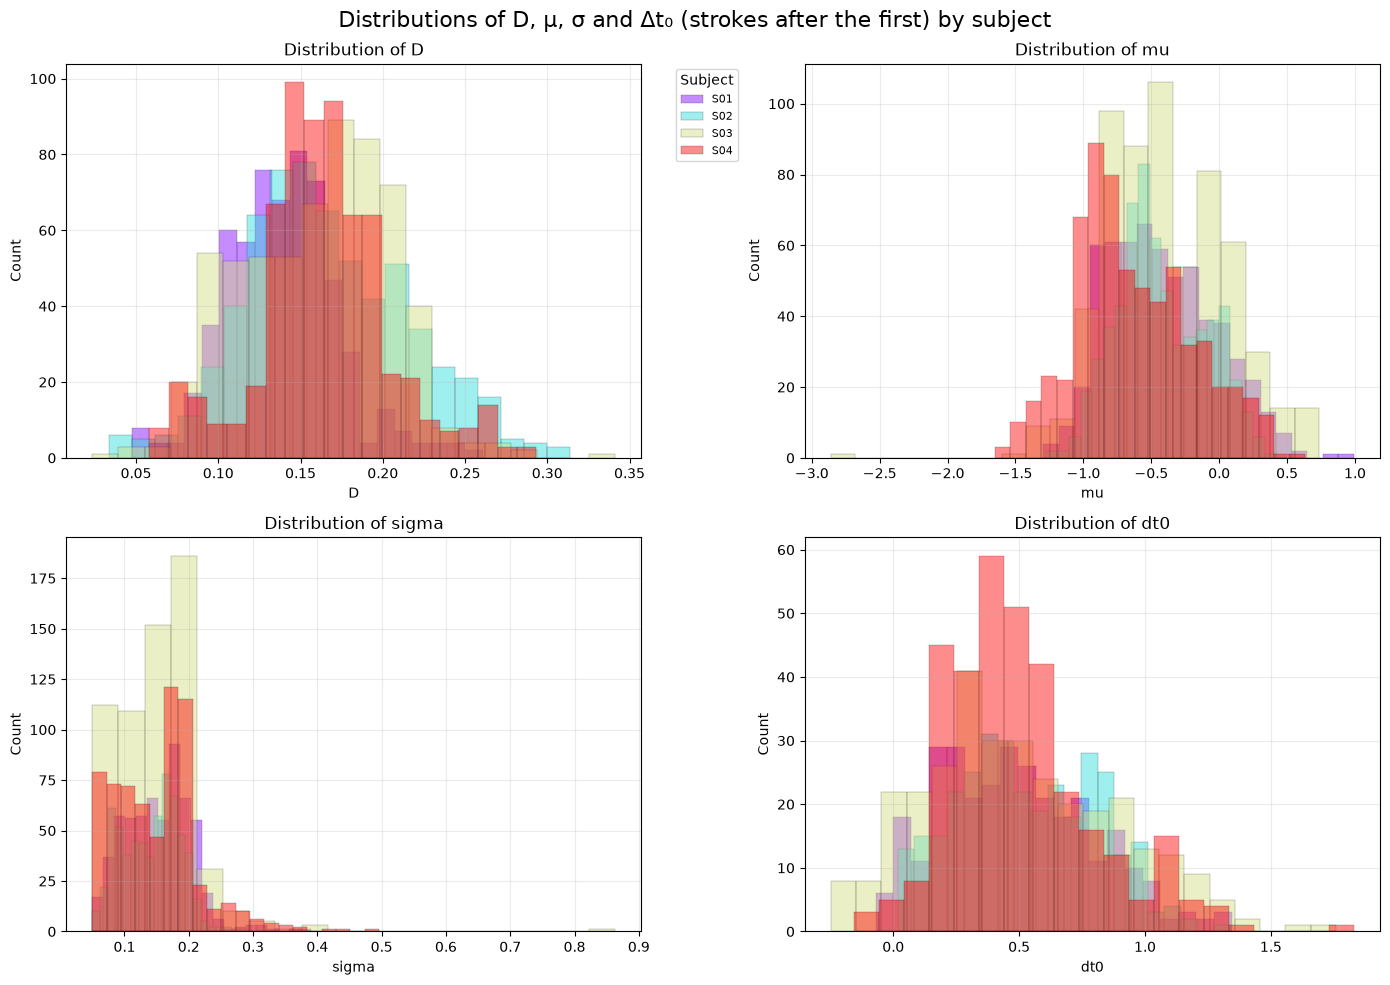

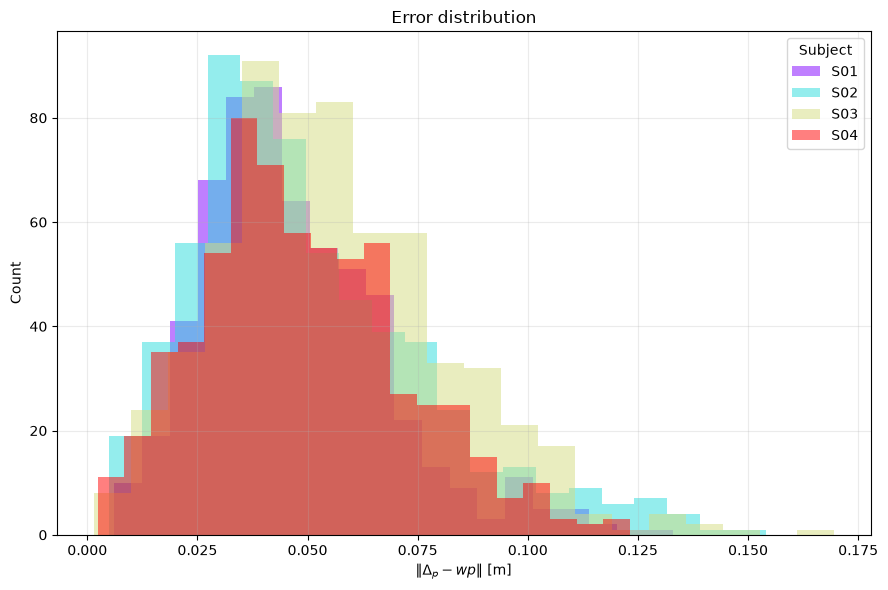

||delta_p - wp|| / ||wp||: median 0.369 | 90th pct 0.728
u_s vs previous u_e (0 with shared junction tangents): median 29.414 deg | max 160.019 deg
First stroke, u_s vs chord direction: median 25.8 deg | 90th pct 54.8 deg


In [14]:
def angle_deg(a, b):
    """Angle between two directions, in degrees."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    cos = a @ b / max(np.linalg.norm(a) * np.linalg.norm(b), 1e-12)
    return float(np.degrees(np.arccos(np.clip(cos, -1.0, 1.0))))


plot_data = final_database.copy()

# D of every stroke: arc length of its Bezier segment, the same quantity used as lognormal amplitude
plot_data["D"] = [
    BezierOptimization._arc_length(ls, le, np.zeros(3), np.asarray(dp, dtype=float),
                                   np.asarray(us, dtype=float), np.asarray(ue, dtype=float))
    for ls, le, dp, us, ue in zip(plot_data["lambda_s"], plot_data["lambda_e"], plot_data["delta_p"],
                                  plot_data["u_s"], plot_data["u_e"])
]
plot_data["delta_p_wp_distance"] = [
    np.linalg.norm(np.asarray(dp, dtype=float) - np.asarray(wp, dtype=float))
    for dp, wp in zip(plot_data["delta_p"], plot_data["wp"])
]

subjects = sorted(plot_data["subject"].unique())
colors = plt.cm.rainbow(np.linspace(0, 1, len(subjects)))

# Distributions of the timing parameters and of D, per subject
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, metric in zip(axes.ravel(), ["D", "mu", "sigma", "dt0"]):
    for subject, color in zip(subjects, colors):
        rows = (plot_data["subject"] == subject) & ((metric != "dt0") | (plot_data["stroke_number"] > 0))
        ax.hist(plot_data.loc[rows, metric].dropna(), bins=20, alpha=0.45,
                color=color, label=subject, edgecolor="black", linewidth=0.3)
    ax.set_title(f"Distribution of {metric}")
    ax.set_xlabel(metric)
    ax.set_ylabel("Count")
    ax.grid(alpha=0.25)
axes[0, 0].legend(title="Subject", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
fig.suptitle("Distributions of D, μ, σ and Δt₀ (strokes after the first) by subject", fontsize=16)
plt.tight_layout()
plt.show()

# Execution error: distance between the reached point and the target waypoint
plt.figure(figsize=(9, 6))
for subject, color in zip(subjects, colors):
    plt.hist(plot_data.loc[plot_data["subject"] == subject, "delta_p_wp_distance"].dropna(),
             bins=20, alpha=0.5, color=color, label=subject)
plt.title("Error distribution")
plt.xlabel(r"$\|\Delta_p - wp\|$ [m]")
plt.ylabel("Count")
plt.grid(alpha=0.25)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

wp_norm = plot_data["wp"].apply(np.linalg.norm)
rel_error = plot_data["delta_p_wp_distance"] / wp_norm.clip(lower=1e-9)
print(f"||delta_p - wp|| / ||wp||: median {rel_error.median():.3f} | 90th pct {rel_error.quantile(0.9):.3f}")

# Start tangents: inherited from the previous end tangent, chord direction for the first stroke
has_prev = plot_data["stroke_number"] > 0
junction_angle = [angle_deg(us, ue) for us, ue in zip(plot_data.loc[has_prev, "u_s"], plot_data.loc[has_prev, "u_e_previous"])]
first_angle = [angle_deg(us, dp) for us, dp in zip(plot_data.loc[~has_prev, "u_s"], plot_data.loc[~has_prev, "delta_p"])]
if junction_angle:
    print(f"u_s vs previous u_e (0 with shared junction tangents): median {np.median(junction_angle):.3f} deg | "
          f"max {np.max(junction_angle):.3f} deg")
if first_angle:
    print(f"First stroke, u_s vs chord direction: median {np.median(first_angle):.1f} deg | "
          f"90th pct {np.percentile(first_angle, 90):.1f} deg")

In [15]:
def prev_vector(series, dim):
    """Previous-stroke column -> list of float32 arrays; strokes without a predecessor get zeros
    (they are masked anyway and flagged by `is_first`)."""
    out = []
    for v in series:
        missing = v is None or (isinstance(v, float) and np.isnan(v))
        out.append(np.zeros(dim, dtype=np.float32) if missing else np.asarray(v, dtype=np.float32).reshape(dim))
    return out


data = final_database.copy()

formatted_data = pd.DataFrame({
    "subject": data["subject"].to_numpy(),
    "task": data["task"].to_numpy(),
    "stroke_number": data["stroke_number"].to_numpy(),
    "is_first": (data["stroke_number"] == 0).to_numpy().astype(np.float32),
    # conditioning: waypoint vectors in the stroke frame (start = origin)
    "wp": data["wp"],
    "wp_n": data["wp_n"],
})
# network targets (delta_p is also a target: the stroke starts at zero and has to reach it)
for key in TARGET_KEYS:
    formatted_data[key] = data[key].to_numpy() if KEY_DIMS[key] == 1 else data[key]
# previous stroke: same quantities as the outputs, WITHOUT delta_p
for key in PREV_KEYS:
    name = key[len("prev_"):]
    formatted_data[key] = pd.Series(prev_vector(data[f"{name}_previous"], KEY_DIMS[name]),
                                    index=formatted_data.index, dtype=object)

formatted_data.head(10)

,subject,task,stroke_number,is_first,wp,wp_n,dt0,mu,sigma,lambda_s,lambda_e,u_e,delta_p,prev_dt0,prev_mu,prev_sigma,prev_lambda_s,prev_lambda_e,prev_u_e
0,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.000,-0.011085,0.102214,0.049982,0.056200,"(-0.09289958722098655, 0.9348327345548373, -0....","(0.10371880059075336, 0.059843993339055025, -0...",[0.0],[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
1,S01,BURSTc_XY,1,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]",0.782,-0.730318,0.190991,0.036180,0.038540,"(-0.9402245435424963, -0.24033583382078355, 0....","(-0.09716147103264361, 0.02884637293620681, -0...",[0.0],[-0.011085286],[0.10221391],[0.049982477],[0.056200296],"[-0.09289959, 0.93483275, -0.34272063]"
2,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.000,-0.279243,0.143431,0.053156,0.054529,"(-0.12750962089906315, 0.9328373199398793, -0....","(0.10558556222114279, 0.06166192333448074, -0....",[0.0],[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
3,S01,BURSTc_XY,1,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]",0.580,-0.766796,0.211181,0.025515,0.050238,"(-0.9878713179739957, -0.05468535425224954, 0....","(-0.08437866052838575, 0.033816326564298387, -...",[0.0],[-0.27924296],[0.14343129],[0.053156313],[0.05452855],"[-0.12750962, 0.9328373, -0.33698046]"
4,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.000,0.009093,0.117175,0.065210,0.061721,"(-0.45514076154921784, 0.8191119946113442, -0....","(0.09014648924495403, 0.07748150729276071, -0....",[0.0],[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
5,S01,BURSTc_XY,1,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]",0.864,-0.894429,0.211561,0.001000,0.057561,"(-0.9745294787386041, -0.1502428229583023, 0.1...","(-0.07863722893820692, 0.02104688130279775, -0...",[0.0],[0.009092815],[0.11717529],[0.06521045],[0.061720937],"[-0.45514077, 0.819112, -0.3491453]"
6,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.000,0.137379,0.087494,0.101689,0.002969,"(0.49460709796839625, 0.7166320310066812, -0.4...","(0.10342995150896793, 0.02037846204975123, -0....",[0.0],[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
7,S01,BURSTc_XY,1,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]",0.888,-0.596108,0.187996,0.061639,0.027946,"(-0.9874685947156834, -0.040439792975539124, 0...","(-0.08722250359514416, 0.06615814067166575, -0...",[0.0],[0.13737881],[0.08749408],[0.10168896],[0.0029689388],"[0.4946071, 0.716632, -0.49173403]"
8,S01,BURSTc_XY,0,1.0,"[0.1312, 0.039, 0.0]","[0.0, 0.078, 0.0]",0.000,-0.520541,0.119402,0.035461,0.033120,"(0.778302561534642, 0.511409404412926, -0.3642...","(0.09177130096489872, 0.0093040202074995, -0.0...",[0.0],[0.0],[0.0],[0.0],[0.0],"[0.0, 0.0, 0.0]"
9,S01,BURSTc_XY,1,0.0,"[-0.1312, 0.039, 0.0]","[-0.1312, 0.039, 0.0]",0.298,-0.607996,0.211449,0.056000,0.062855,"(-0.9517398389760936, -0.06843357200482059, 0....","(-0.07839562101335765, 0.07703128328345758, -0...",[0.0],[-0.5205407],[0.11940243],[0.03546058],[0.033119645],"[0.77830255, 0.5114094, -0.36428773]"


## Training

### Hyperparameters and validation split

The validation set is made of whole subjects (`VALIDATION_SPLIT = "subject"`: generalisation to new people) or whole tasks (`"task"`: generalisation to new waypoint configurations).

In [16]:
# ---- validation split ----
VALIDATION_SPLIT = "subject"    # "subject": held-out subjects | "task": held-out tasks
VALIDATION_FRACTION = 0.15      # fraction of the subjects (or of the tasks) used for validation
SPLIT_SEED = 0

# ---- model hyperparameters, sized for a dataset of about a thousand strokes ----
EMBEDDING_DIM = 16        # width of the waypoint and previous-stroke embeddings
LSTM_DIM = 32             # recurrent width
LSTM_COUNT = 1            # recurrent layers
MDN_HIDDEN_DIM = 64       # hidden layer of the mixture head
MIXTURE_COMPONENTS = 4    # Gaussian components
MIN_DIAG = 0.05           # floor of the Cholesky diagonal, in standardized units

# ---- training hyperparameters ----
BATCH_SIZE = 64
EPOCHS = 400
LR = 1e-3
WEIGHT_DECAY = 1e-4       # decoupled weight decay (AdamW)
GRAD_CLIP = 1.0
PATIENCE = 40             # epochs without improvement of the validation NLL before stopping

In [17]:
def split_by_group(data, column, fraction, seed):
    """Train / validation split in which every value of `column` (subject or task) falls on one side only."""
    groups = np.array(sorted(data[column].unique()))
    np.random.default_rng(seed).shuffle(groups)
    n_val = min(max(1, int(round(fraction * len(groups)))), len(groups) - 1)
    val_groups = set(groups[:n_val].tolist())
    is_val = data[column].isin(val_groups)
    return data[~is_val].reset_index(drop=True), data[is_val].reset_index(drop=True), sorted(val_groups)


if VALIDATION_SPLIT not in ("subject", "task"):
    raise ValueError("VALIDATION_SPLIT must be 'subject' or 'task'")

train_df, val_df, val_groups = split_by_group(formatted_data, VALIDATION_SPLIT, VALIDATION_FRACTION, SPLIT_SEED)
train_ds, val_ds = StrokeDataset(train_df), StrokeDataset(val_df)
train_loader = StrokeDataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = StrokeDataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
print(f"split by {VALIDATION_SPLIT} | train strokes: {len(train_ds)} | val strokes: {len(val_ds)} | "
      f"validation {VALIDATION_SPLIT}s: {val_groups}")

split by subject | train strokes: 1869 | val strokes: 610 | validation subjects: ['S03']


In [18]:
# ---- standardization ----
@torch.no_grad()
def compute_stats(dataset, eps=1e-8):
    """(mean, std) per key, from a StrokeDataset.
    wp, wp_n and delta_p share ONE zero-mean isotropic scale: the stroke origin stays at 0, the three
    vectors stay in the same units and delta_p - wp keeps its geometric meaning (it is just rescaled)."""
    t = dataset.tensors
    stats = {k: (t[k].mean(0), t[k].std(0).clamp_min(eps)) for k in STAT_KEYS}
    pooled = torch.cat([t[k].reshape(-1) for k in GEOM_SHARED_KEYS])
    scale = pooled.pow(2).mean().sqrt().clamp_min(eps).item()
    for k in GEOM_SHARED_KEYS:
        d = t[k].size(1)
        stats[k] = (torch.zeros(d), torch.full((d,), scale))
    return stats


def _standardize(x, stat, device):
    m, s = stat
    x = x.float().to(device).reshape(x.size(0), -1)
    return (x - m.to(device)) / s.to(device)


def normalize_batch(batch, stats, device):
    """Standardize a batch (or a whole dataset dict) with the training statistics.
    prev_* reuse the statistics of the matching target and are zeroed for first strokes
    (no previous stroke): together with the `is_first` flag this is the start-of-sequence input."""
    is_first = batch["is_first"].float().to(device).reshape(-1, 1)
    out = {"is_first": is_first}
    for k in STAT_KEYS:
        out[k] = _standardize(batch[k], stats[k], device)
    for k in PREV_KEYS:
        out[k] = _standardize(batch[k], stats[k[len("prev_"):]], device) * (1.0 - is_first)
    return out


@torch.no_grad()
def stack_targets(dataset, stats):
    nb = normalize_batch(dataset.tensors, stats, "cpu")
    return torch.cat([nb[k] for k in TARGET_KEYS], dim=-1)


stats = compute_stats(train_ds)

# ---- model ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INPUT_DIM = 2 * train_ds.tensors["wp"].size(1) + 1                     # wp, wp_n, is_first
OUTPUT_DIM = sum(train_ds.tensors[k].size(1) for k in TARGET_KEYS)     # dt0, mu, sigma, lambda_s, lambda_e, u_e, delta_p
RECUR_DIM = sum(train_ds.tensors[k].size(1) for k in PREV_KEYS)        # same without delta_p


def model_config():
    """Constructor arguments of GenerativeModel (also stored in the checkpoints)."""
    return dict(
        input_dim=int(INPUT_DIM), embedding_dim=int(EMBEDDING_DIM), LSTM_dim=int(LSTM_DIM),
        LSTM_count=int(LSTM_COUNT), output_dim=int(OUTPUT_DIM), mixture_components=int(MIXTURE_COMPONENTS),
        recur_dim=int(RECUR_DIM), min_diag=float(MIN_DIAG), mdn_hidden_dim=int(MDN_HIDDEN_DIM),
    )


def build_model():
    """Fresh, initialised model."""
    model = GenerativeModel(**model_config()).to(device)
    model.set_weights(stack_targets(train_ds, stats).to(device))
    return model


n_parameters = sum(p.numel() for p in build_model().parameters())
print(f"input {INPUT_DIM} | output {OUTPUT_DIM} | previous-stroke {RECUR_DIM} | "
      f"parameters {n_parameters} for {len(train_ds)} training strokes")

input 7 | output 11 | previous-stroke 8 | parameters 32168 for 1869 training strokes


### Training loop

Plain mixture NLL or nGEM, selectable. The best model is chosen on the **validation mixture NLL** with both losses: the value of the nGEM surrogate is not a quantity that can be compared across epochs.

In [19]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def make_loss_fn(loss_name, ngem_kwargs=None):
    """Both options return (loss to backpropagate, detached mixture NLL)."""
    if loss_name == "nll":
        return lambda model, batch: mdn_nll_loss(model, batch, device)
    if loss_name == "ngem":
        kwargs = dict(fisher_mode="closed_form", natural_mixing=True, pi_floor=1e-4)
        kwargs.update(ngem_kwargs or {})
        return lambda model, batch: ngem_loss(model, batch, device, return_nll=True, **kwargs)
    raise ValueError("loss_name must be 'nll' or 'ngem'")


@torch.no_grad()
def evaluate_nll(model, loader, stats):
    """Mean mixture NLL on a loader: the model-selection metric for BOTH losses."""
    model.eval()
    total, count = 0.0, 0
    for raw in loader:
        batch = normalize_batch(raw, stats, device)
        x, prev, target = model_io(batch, device)
        means, scale_tril, logits = model(x, prev_output=prev)
        size = x.size(0)
        total += mixture_nll(means, scale_tril, logits, target).item() * size
        count += size
    return total / count


def save_checkpoint(path, model, stats, loss_name, epoch, val_nll):
    torch.save({
        "model_state": model.state_dict(),
        "stats": stats,
        "config": model_config(),
        "target_keys": list(TARGET_KEYS),
        "prev_keys": list(PREV_KEYS),
        "loss": loss_name,
        "epoch": epoch,
        "val_nll": val_nll,
    }, path)


def load_checkpoint(path):
    """-> (model in eval mode, stats, checkpoint dict)."""
    ckpt = torch.load(path, map_location=device, weights_only=False)
    if ckpt["target_keys"] != list(TARGET_KEYS) or ckpt["prev_keys"] != list(PREV_KEYS):
        raise ValueError("the checkpoint was trained with different TARGET_KEYS / PREV_KEYS")
    model = GenerativeModel(**ckpt["config"]).to(device)
    model.load_state_dict(ckpt["model_state"])
    model.eval()
    return model, ckpt["stats"], ckpt


def train_model(model, train_loader, val_loader, stats, loss_name="nll", epochs=100, lr=1e-3,
                weight_decay=0.0, grad_clip=1.0, ngem_kwargs=None, ckpt_path="best_stroke_model.pt",
                patience=None, verbose=True):
    """AdamW training; the checkpoint with the lowest validation NLL is saved and restored at the end."""
    loss_fn = make_loss_fn(loss_name, ngem_kwargs)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_epoch, history = float("inf"), 0, []

    for epoch in range(1, epochs + 1):
        model.train()
        total, count = 0.0, 0
        for raw in train_loader:
            batch = normalize_batch(raw, stats, device)
            loss, nll = loss_fn(model, batch)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()
            size = batch["wp"].size(0)
            total += nll.item() * size
            count += size

        train_nll = total / count
        val_nll = evaluate_nll(model, val_loader, stats)
        history.append({"epoch": epoch, "train_nll": train_nll, "val_nll": val_nll})
        if not (np.isfinite(train_nll) and np.isfinite(val_nll)):
            print(f"epoch {epoch}: non-finite loss, stopping")
            break

        improved = val_nll < best_val
        if improved:
            best_val, best_epoch = val_nll, epoch
            save_checkpoint(ckpt_path, model, stats, loss_name, epoch, val_nll)
        if verbose:
            print(f"epoch {epoch:3d} | train NLL {train_nll:9.4f} | val NLL {val_nll:9.4f}" + ("  *" if improved else ""))
        if patience is not None and epoch - best_epoch >= patience:
            print(f"no improvement for {patience} epochs: early stop")
            break

    if best_epoch == 0:
        raise RuntimeError("no finite validation loss: nothing was saved")
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=False)["model_state"])
    print(f"best epoch {best_epoch} | val NLL {best_val:.4f} | saved to {ckpt_path}")
    return history


def plot_history(history, title=None):
    epochs = [h["epoch"] for h in history]
    best = min(history, key=lambda h: h["val_nll"])
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(epochs, [h["train_nll"] for h in history], label="train NLL")
    ax.plot(epochs, [h["val_nll"] for h in history], label="validation NLL")
    ax.axvline(best["epoch"], color="gray", linestyle=":", label=f"best epoch ({best['epoch']})")
    ax.set_xlabel("epoch")
    ax.set_ylabel("mixture NLL")
    ax.set_title(title or "Training history")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

epoch   1 | train NLL   18.1597 | val NLL   14.8794  *
epoch   2 | train NLL   12.6042 | val NLL   12.5517  *
epoch   3 | train NLL   10.1624 | val NLL   11.5642  *
epoch   4 | train NLL    8.7534 | val NLL   11.3866  *
epoch   5 | train NLL    7.7167 | val NLL   10.6333  *
epoch   6 | train NLL    6.8271 | val NLL   11.0590
epoch   7 | train NLL    6.0913 | val NLL   10.4033  *
epoch   8 | train NLL    5.4988 | val NLL   10.4736
epoch   9 | train NLL    5.0735 | val NLL   10.2811  *
epoch  10 | train NLL    4.6694 | val NLL   10.1184  *
epoch  11 | train NLL    4.3982 | val NLL    9.8254  *
epoch  12 | train NLL    4.0423 | val NLL   11.0586
epoch  13 | train NLL    3.7971 | val NLL   11.0099
epoch  14 | train NLL    3.6465 | val NLL   10.8429
epoch  15 | train NLL    3.4599 | val NLL   10.6963
epoch  16 | train NLL    3.3499 | val NLL   10.3819
epoch  17 | train NLL    3.1657 | val NLL   10.0799
epoch  18 | train NLL    3.0134 | val NLL    9.6607  *
epoch  19 | train NLL    2.8779 | 

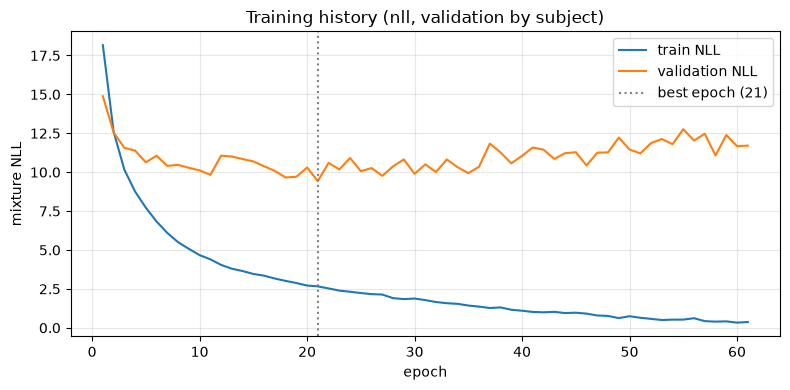

In [20]:
LOSS = "nll"        # "nll": plain mixture NLL | "ngem": natural-gradient EM surrogate
NGEM_KWARGS = dict(fisher_mode="closed_form", natural_mixing=True, pi_floor=1e-4)   # used only if LOSS == "ngem"
CKPT_PATH = f"best_stroke_model_{LOSS}_{VALIDATION_SPLIT}.pt"

set_seed(0)
model = build_model()
history = train_model(model, train_loader, val_loader, stats, loss_name=LOSS, epochs=EPOCHS, lr=LR,
                      weight_decay=WEIGHT_DECAY, grad_clip=GRAD_CLIP, ngem_kwargs=NGEM_KWARGS,
                      ckpt_path=CKPT_PATH, patience=PATIENCE)
plot_history(history, title=f"Training history ({LOSS}, validation by {VALIDATION_SPLIT})")

## Generation

Given a task and a seed the stroke network is sampled **autoregressively**, one stroke per waypoint (stroke k aims at W[k+1]). Each stroke is conditioned on its waypoint vectors, expressed in the frame whose origin is where the previous generated stroke ended, and on the previous generated stroke. Then:

* the onset of every stroke is the onset of the previous one plus the generated interval $\Delta t_0$ (the first stroke starts at $t=0$);
* the start tangent of every stroke is the end tangent of the previous one (G1 junction); the first stroke starts along its chord $\Delta p$;
* `D` of every stroke is the arc length of its Bézier segment, and it is the amplitude of its lognormal speed profile (`Stroke`);
* the Bézier chain is traversed with the distance travelled by the model, $S(t)=\sum_k D_k\Phi_k(t)$: the speed along the path is the sum of the lognormals (`StrokeSequence`) and is continuous, and so is the velocity.

In [21]:
LAMBDA_MIN = 1e-3            # same lower bound used when the dataset was built
SIGMA_MIN = 1e-3
Z_TAIL = 2.5758293035489004  # standard-normal quantile of 99.5 %
MAX_SAMPLES = 2_000_000


def _unit(v):
    v = np.asarray(v, dtype=float)
    return v / max(np.linalg.norm(v), 1e-8)


def sample_stroke(model, stats, task, k, start, prev):
    """One autoregressive step. `start` conditions wp / wp_n (as in training); `prev` is the previous stroke or None."""
    wp, wp_n = stroke_deltas(task, k, start)
    is_first = torch.full((1, 1), 1.0 if prev is None else 0.0, device=device)
    x = torch.cat([
        _standardize(torch.from_numpy(wp)[None], stats["wp"], device),
        _standardize(torch.from_numpy(wp_n)[None], stats["wp_n"], device),
        is_first,
    ], dim=-1)

    if prev is None:
        prev_vec = torch.zeros(1, RECUR_DIM, device=device)      # start-of-sequence input, as in training
    else:
        prev_vec = torch.cat([
            _standardize(
                torch.as_tensor(np.asarray(prev[key[len("prev_"):]], dtype=np.float32)).reshape(1, -1),
                stats[key[len("prev_"):]], device)
            for key in PREV_KEYS
        ], dim=-1)

    out = model.sample(x, prev_output=prev_vec).cpu()            # [1, OUTPUT_DIM], standardized

    params, i = {}, 0
    for key in TARGET_KEYS:
        mean, std = stats[key][0].cpu(), stats[key][1].cpu()
        d = mean.numel()
        params[key] = (out[:, i:i + d] * std + mean).numpy()[0]
        i += d

    # the network is Gaussian on R^n: project the samples back on the valid set
    delta_p = params["delta_p"].astype(np.float64)
    return {
        "dt0": float(params["dt0"][0]),
        "mu": float(params["mu"][0]),
        "sigma": max(float(params["sigma"][0]), SIGMA_MIN),
        "lambda_s": max(float(params["lambda_s"][0]), LAMBDA_MIN),
        "lambda_e": max(float(params["lambda_e"][0]), LAMBDA_MIN),
        "u_e": _unit(params["u_e"]),
        "delta_p": delta_p,
        # start tangent: end tangent of the previous stroke (G1 junction), chord direction for the first stroke
        "u_s": _unit(delta_p) if prev is None else np.asarray(prev["u_e"], dtype=np.float64),
    }


@torch.no_grad()
def generate_task(model, stats, task, seed, n_strokes=None, wp_reference=WP_REFERENCE):
    """All the stroke parameters needed to execute `task`, for a given seed."""
    if task not in WAYPOINTS_BY_TASK:
        raise KeyError(f"unknown task '{task}'. Available: {sorted(WAYPOINTS_BY_TASK)}")
    waypoints = WAYPOINTS_BY_TASK[task]
    n_strokes = len(waypoints) - 1 if n_strokes is None else int(n_strokes)

    set_seed(seed)
    model.eval()
    strokes, prev = [], None
    chain = waypoints[0].astype(np.float64)          # where the previous stroke ended
    for k in range(n_strokes):
        # conditioning frame: same convention used to build the dataset
        start = chain if wp_reference == "actual" else waypoints[min(k, len(waypoints) - 1)].astype(np.float64)
        stroke = sample_stroke(model, stats, task, k, start, prev)
        stroke["stroke_number"] = k
        stroke["t0"] = (0.0 if prev is None else prev["t0"]) + stroke["dt0"]   # time origin: onset of the first stroke
        stroke["p0"] = chain.copy()
        stroke["p3"] = chain + stroke["delta_p"]
        chain = stroke["p3"]
        strokes.append(stroke)
        prev = stroke
    return strokes


def travelled_distance(sequence: StrokeSequence, t) -> np.ndarray:
    """Distance covered by the sum of the strokes at the times `t`: S(t) = sum_k D_k Phi_k(t)."""
    t = np.asarray(t, dtype=float)
    travelled = np.zeros_like(t)
    for stroke in sequence:
        after = t > stroke.to
        phi = 0.5 * (1.0 + erf((np.log(t[after] - stroke.to) - stroke.mu) / (stroke.sigma * np.sqrt(2.0))))
        travelled[after] += stroke.D * phi
    return travelled


def build_task_curve(strokes, dt=0.005):
    """
    Speed profiles and Bezier path of a generated stroke sequence (sampled every `dt` seconds).
    Segment k of the Bezier chain has length D_k and the chain is traversed with the distance
    travelled by the model, S(t) = sum_k D_k Phi_k(t): the path speed is the sum of the lognormals.
    """
    for s in strokes:
        s["D"] = BezierOptimization._arc_length(s["lambda_s"], s["lambda_e"], s["p0"], s["p3"], s["u_s"], s["u_e"])
    sequence = StrokeSequence([Stroke(D=s["D"], mu=s["mu"], sigma=s["sigma"], to=s["t0"]) for s in strokes])

    # time window: 0.5 % quantile of the earliest stroke -> 99.5 % quantile of the latest one
    t_start = min(s.to + np.exp(s.mu - Z_TAIL * s.sigma) for s in sequence)
    t_end = max(s.to + np.exp(s.mu + Z_TAIL * s.sigma) for s in sequence)
    if not (np.isfinite(t_start) and np.isfinite(t_end)) or (t_end - t_start) / dt > MAX_SAMPLES:
        raise ValueError("the generated timing is degenerate: try another seed")
    t = np.arange(t_start, t_end + dt, dt)

    v_all = np.vstack([StrokeSequence([stroke]).v_array(t) for stroke in sequence])
    v_tot = v_all.sum(axis=0)
    travelled = travelled_distance(sequence, t)

    # segment reached at each time and arc-length fraction inside that segment
    starts = np.concatenate([[0.0], np.cumsum([s.D for s in sequence])])
    distance = np.clip(travelled, 0.0, starts[-1])
    segment = np.clip(np.searchsorted(starts, distance, side="right") - 1, 0, len(strokes) - 1)

    points = np.empty((t.size, 3))
    for k, s in enumerate(strokes):
        mask = segment == k
        if not np.any(mask):
            continue
        fraction = (distance[mask] - starts[k]) / s["D"]
        param = BezierOptimization._arclength_parameters(fraction, s["lambda_s"], s["lambda_e"], s["p0"], s["p3"], s["u_s"], s["u_e"])
        points[mask] = BezierOptimization._bezier(param, s["lambda_s"], s["lambda_e"], s["p0"], s["p3"], s["u_s"], s["u_e"])

    # samples at which the movement crosses each junction between consecutive segments
    junctions = np.minimum(np.searchsorted(travelled, starts[1:-1]), t.size - 1)

    # local extrema of the total speed; first and last samples count as minima
    minima = np.unique(np.r_[0, find_peaks(-v_tot)[0], t.size - 1])
    maxima = find_peaks(v_tot)[0]

    return {
        "strokes": strokes, "sequence": sequence, "t": t, "v_all": v_all, "v_tot": v_tot,
        "points": points, "path": Curve(x=points[:, 0], y=points[:, 1], z=points[:, 2], t=t),
        "travelled": travelled, "junctions": junctions, "minima": minima, "maxima": maxima,
        "path_speed": np.linalg.norm(np.gradient(points, t, axis=0), axis=1),
    }

In [22]:
def plot_speed(res, title="", overlay_path_speed=True):
    """Superposition of the lognormal speed profiles."""
    t, strokes = res["t"], res["strokes"]
    n = len(strokes)
    colors = plt.cm.coolwarm_r(np.linspace(0, 1, n))

    fig, ax = plt.subplots(figsize=(12, 5))
    for k in range(n):
        ax.plot(t, res["v_all"][k], color=colors[k], linewidth=1.3, label=f"stroke {k}" if n <= 12 else None)
        ax.fill_between(t, res["v_all"][k], color=colors[k], alpha=0.12)
    ax.plot(t, res["v_tot"], color="black", linewidth=2, label="sum of lognormals")
    if overlay_path_speed:
        ax.plot(t, res["path_speed"], color="black", linestyle="--", linewidth=1, label="speed of the Bezier path")
    ax.scatter(t[res["minima"]], res["v_tot"][res["minima"]], color="tab:blue", s=45, zorder=4, label="speed minima")
    ax.scatter(t[res["maxima"]], res["v_tot"][res["maxima"]], color="tab:orange", s=45, zorder=4, label="speed maxima")
    for j, idx in enumerate(res["junctions"]):
        ax.axvline(t[idx], color="tab:red", linestyle=":", linewidth=1, label="junction crossed" if j == 0 else None)
    ax.set_xlabel("time [s]")
    ax.set_ylabel("speed [m/s]")
    ax.set_title(title or "Generated lognormal speed profiles")
    ax.grid(True)
    ax.legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_path(res, task, title=""):
    """Bezier path vs waypoints, with the speed minima / maxima; right: end point error of every stroke."""
    waypoints = WAYPOINTS_BY_TASK[task]
    strokes, pts = res["strokes"], res["points"]

    fig = plt.figure(figsize=(15, 6))
    ax1 = fig.add_subplot(1, 2, 1, projection="3d")
    ax1.plot(*pts.T, color="tab:red", linewidth=2, label="generated (Bezier splines)")
    ax1.plot(*waypoints.T, color="black", linestyle="--", linewidth=1, marker="o", markersize=6, label="waypoints")
    for k, w in enumerate(waypoints):
        ax1.text(w[0], w[1], w[2], f" W{k}")
    ax1.scatter(*pts[res["minima"]].T, color="tab:blue", s=45, zorder=4, label="speed minima")
    if len(res["maxima"]):
        ax1.scatter(*pts[res["maxima"]].T, color="tab:orange", s=45, zorder=4, label="speed maxima")
    if len(res["junctions"]):
        ax1.scatter(*pts[res["junctions"]].T, color="tab:red", marker="x", s=60, zorder=5, label="junctions")
    everything = np.vstack([pts, waypoints])
    ax1.set_box_aspect(np.ptp(everything, axis=0).clip(min=1e-9))
    ax1.set_xlabel("X")
    ax1.set_ylabel("Y")
    ax1.set_zlabel("Z")
    ax1.set_title(title or f"Task '{task}': waypoints vs generated path")
    ax1.legend()

    ax2 = fig.add_subplot(1, 2, 2)
    errors = [np.linalg.norm(s["p3"] - waypoints[min(s["stroke_number"] + 1, len(waypoints) - 1)]) for s in strokes]
    ax2.bar(range(len(errors)), errors, color="tab:red", alpha=0.8)
    ax2.set_xlabel("stroke k (target waypoint W[k+1])")
    ax2.set_ylabel(r"$\|$end point $-$ waypoint$\|$ [m]")
    ax2.set_title("End point error")
    ax2.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


def generate_and_plot(model, stats, task, seed, dt=0.005, n_strokes=None, overlay_path_speed=True):
    """Everything needed to execute `task`: stroke parameters + both plots. Returns (strokes, result)."""
    strokes = generate_task(model, stats, task, seed, n_strokes=n_strokes)
    res = build_task_curve(strokes, dt=dt)

    columns = ["stroke_number", "dt0", "t0", "mu", "sigma", "D", "lambda_s", "lambda_e"]
    table = pd.DataFrame([{c: s[c] for c in columns} for s in res["strokes"]])
    table["u_s"] = [tuple(np.round(s["u_s"], 3)) for s in res["strokes"]]
    table["u_e"] = [tuple(np.round(s["u_e"], 3)) for s in res["strokes"]]
    table["delta_p"] = [tuple(np.round(s["delta_p"], 4)) for s in res["strokes"]]
    print(table.to_string(index=False))

    plot_speed(res, title=f"Task '{task}', seed {seed}: lognormal superposition", overlay_path_speed=overlay_path_speed)
    plot_path(res, task, title=f"Task '{task}', seed {seed}: waypoints vs generated path")
    return strokes, res

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number       dt0        t0        mu    sigma        D  lambda_s  lambda_e                    u_s                      u_e                    delta_p
             0 -0.009897 -0.009897  0.422028 0.021002 0.180512  0.059955  0.052884   (0.941, 0.33, 0.075)   (0.663, 0.749, -0.024)   (0.1675, 0.0588, 0.0133)
             1  1.069519  1.059622 -0.621643 0.160752 0.205769  0.081217  0.043406 (0.663, 0.749, -0.024) (-0.561, -0.803, -0.204) (-0.1503, 0.0462, -0.0149)


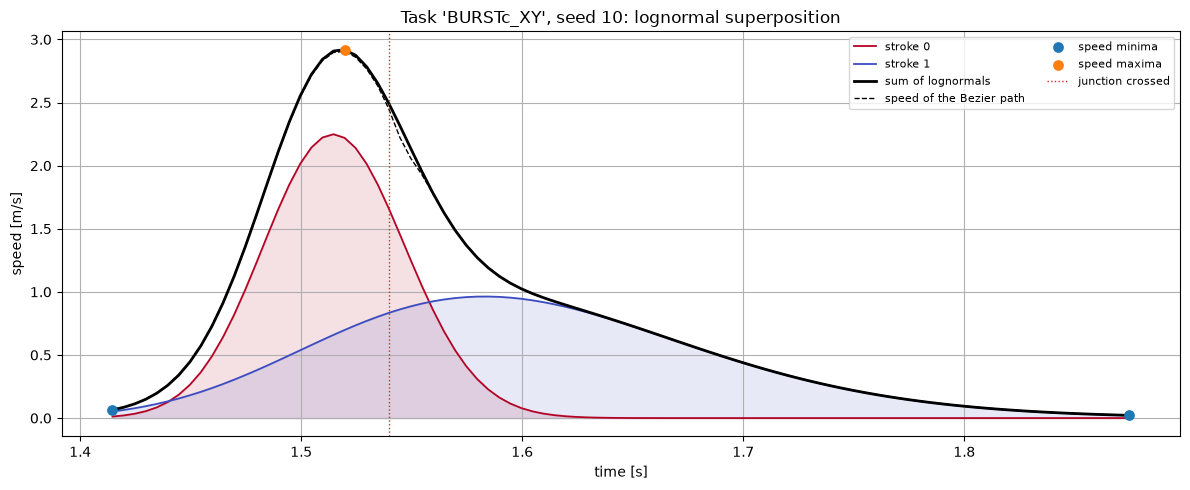

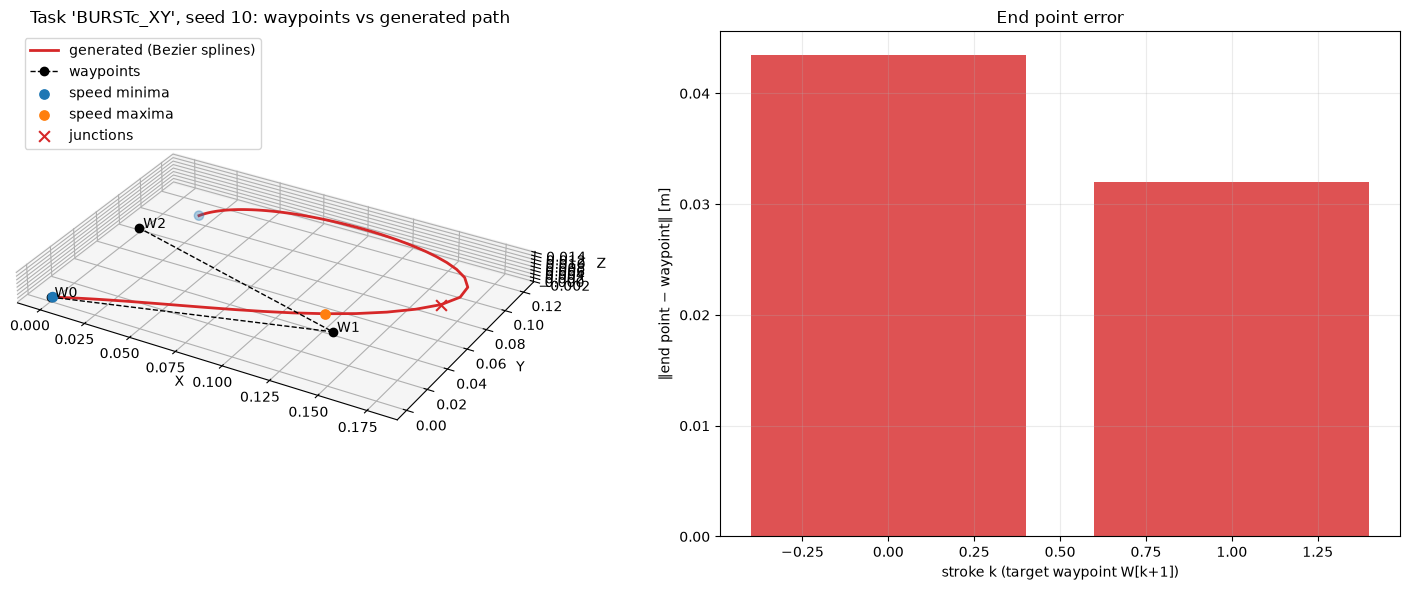

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number      dt0       t0        mu    sigma        D  lambda_s  lambda_e                   u_s                     u_e                    delta_p
             0 0.013619 0.013619  0.047543 0.101665 0.169492  0.074201  0.058860 (0.928, 0.365, -0.07)   (0.243, 0.97, -0.016)  (0.1484, 0.0584, -0.0112)
             1 0.619222 0.632842 -0.343163 0.138410 0.239381  0.089893  0.048744 (0.243, 0.97, -0.016) (-0.645, -0.763, 0.044) (-0.1804, 0.0744, -0.0303)


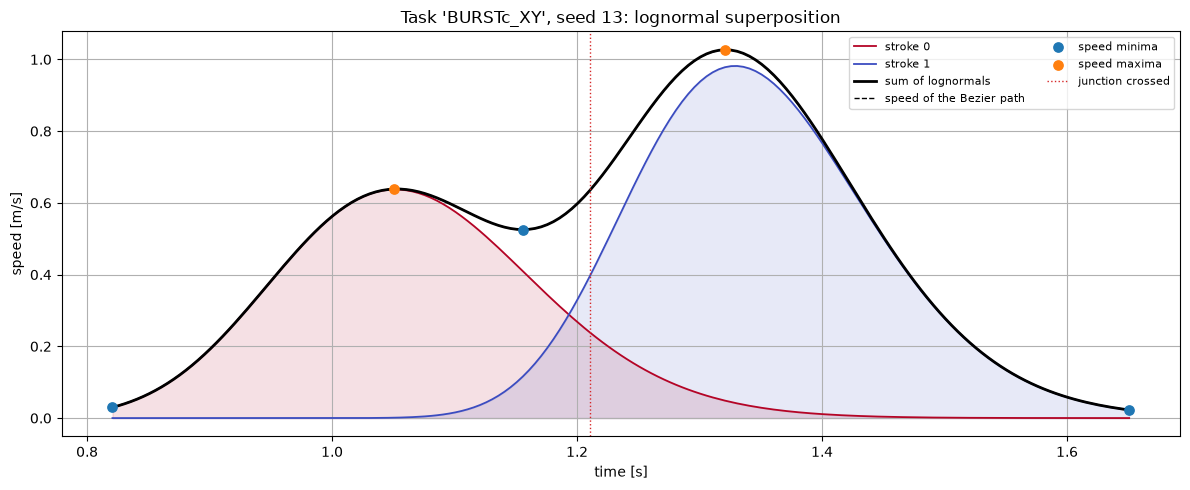

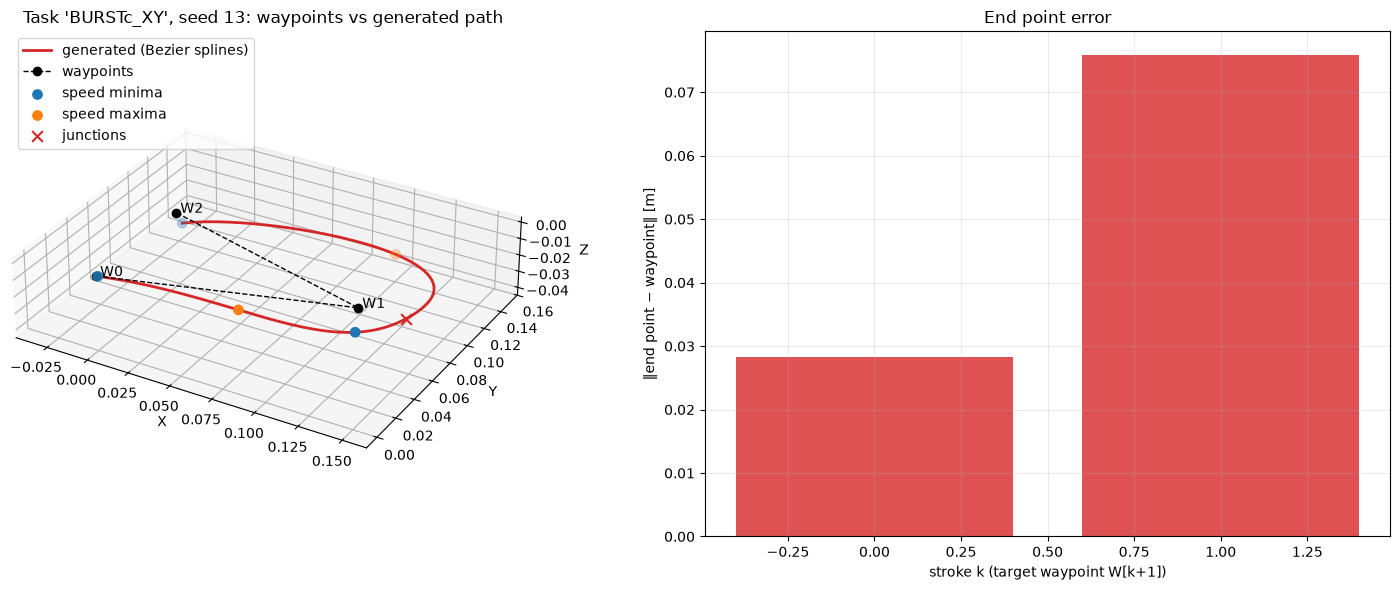

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number      dt0       t0        mu    sigma        D  lambda_s  lambda_e                   u_s                     u_e                   delta_p
             0 0.015394 0.015394 -0.039267 0.076541 0.145000  0.024522  0.052692 (0.962, 0.262, 0.082)    (0.461, 0.83, 0.314)  (0.1334, 0.0363, 0.0114)
             1 0.765249 0.780643 -0.694760 0.190076 0.174475  0.066880  0.022522  (0.461, 0.83, 0.314) (-0.896, -0.438, 0.075) (-0.1362, 0.0548, 0.0077)


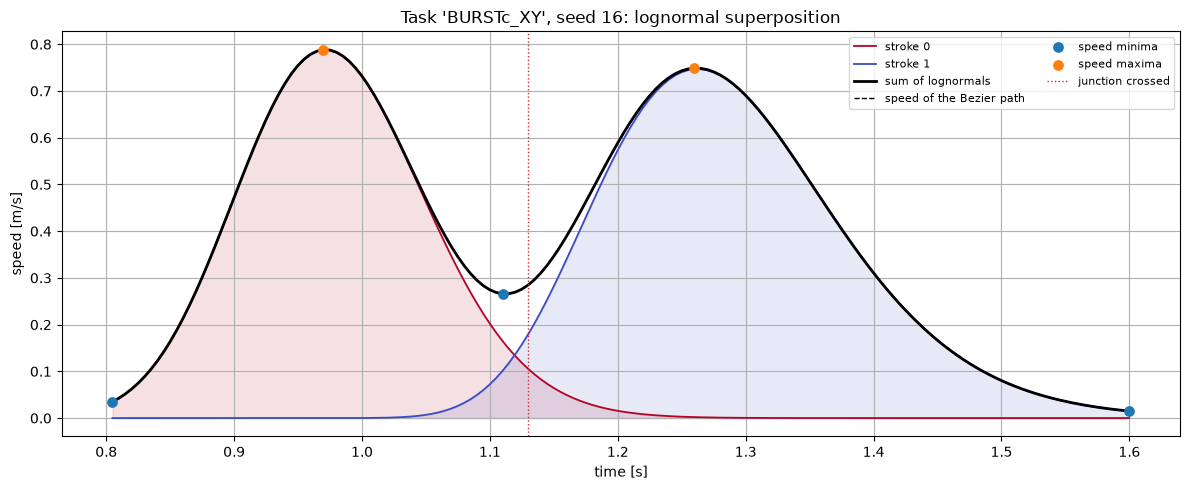

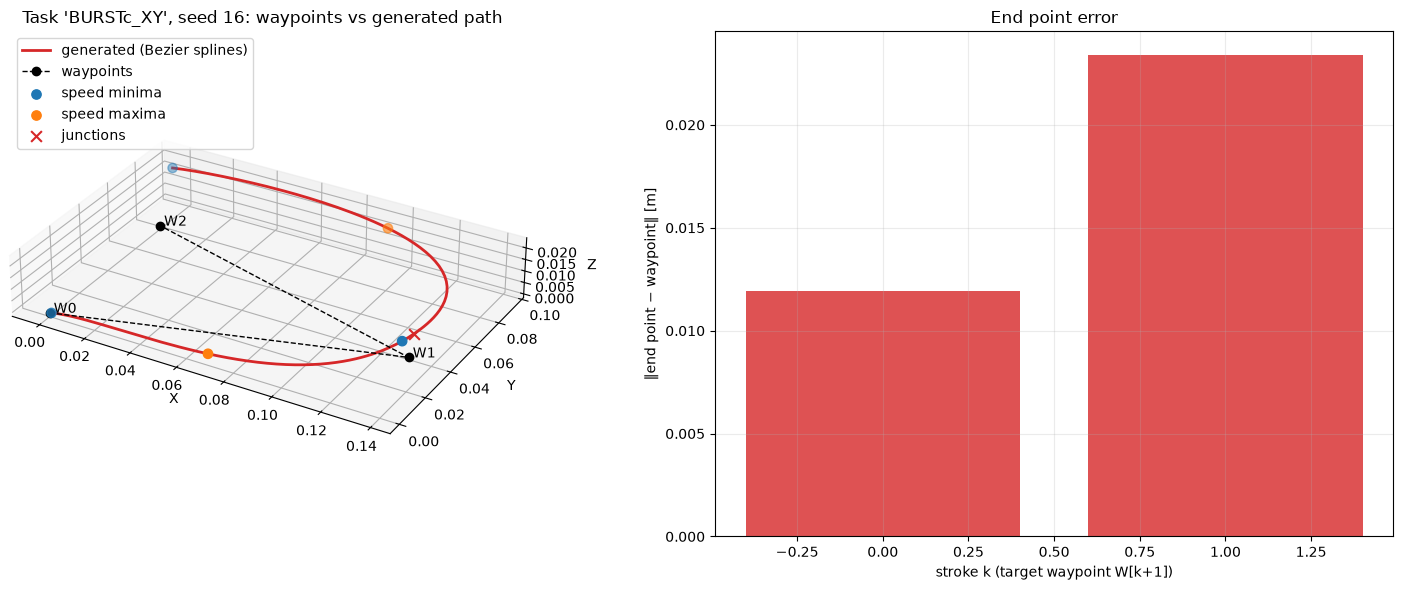

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number      dt0       t0        mu    sigma        D  lambda_s  lambda_e                   u_s                      u_e                  delta_p
             0 0.041612 0.041612 -0.797800 0.136185 0.108866  0.047548  0.015329 (0.984, 0.158, -0.08)    (0.738, 0.643, 0.205) (0.1064, 0.017, -0.0086)
             1 0.342134 0.383746 -0.897904 0.208063 0.104273  0.049151  0.030535 (0.738, 0.643, 0.205) (-0.844, -0.536, -0.002) (-0.0667, 0.004, -0.027)


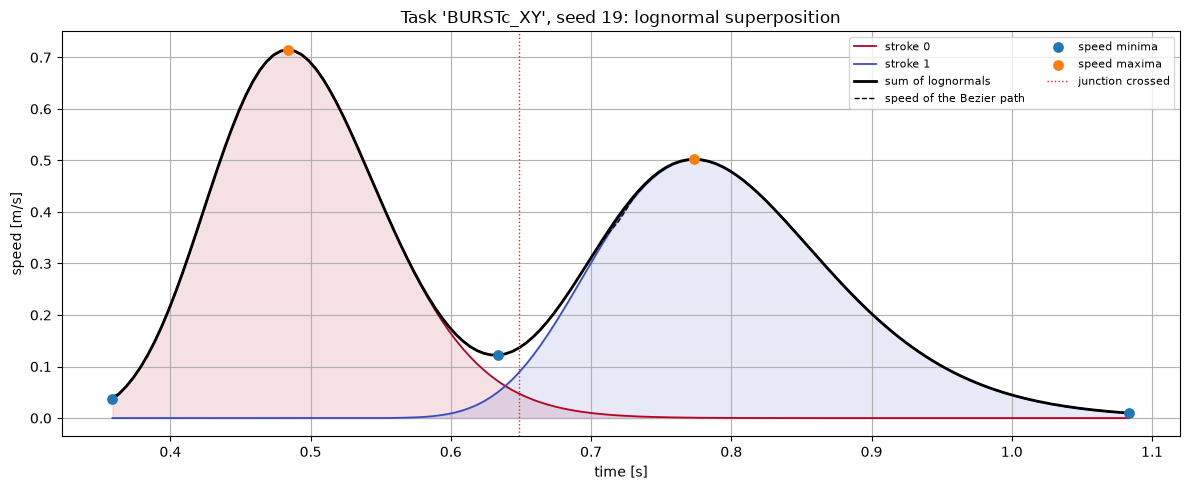

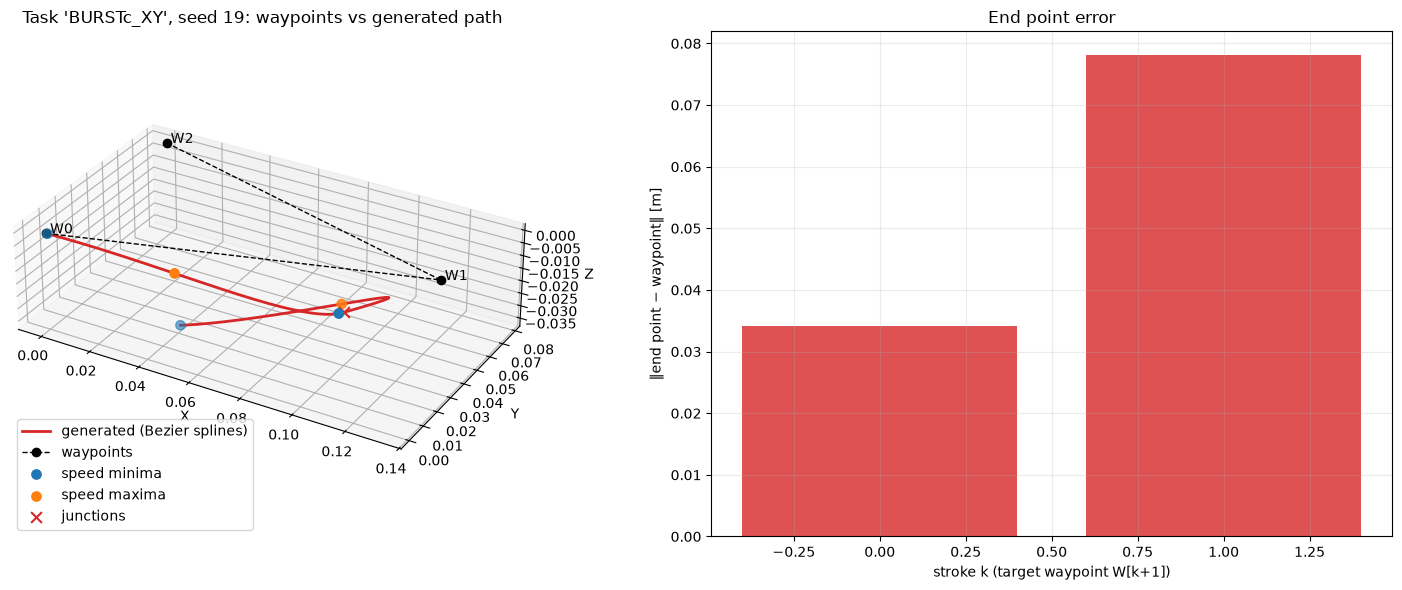

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number       dt0        t0        mu    sigma        D  lambda_s  lambda_e                    u_s                     u_e                    delta_p
             0 -0.018023 -0.018023 -0.427743 0.114375 0.134003   0.00493  0.059975  (0.964, 0.267, 0.002)  (0.267, 0.365, -0.892)   (0.1145, 0.0317, 0.0003)
             1  0.474832  0.456809 -0.791170 0.177593 0.149347   0.04973  0.044539 (0.267, 0.365, -0.892) (-0.954, -0.148, 0.259) (-0.1178, 0.0471, -0.0017)


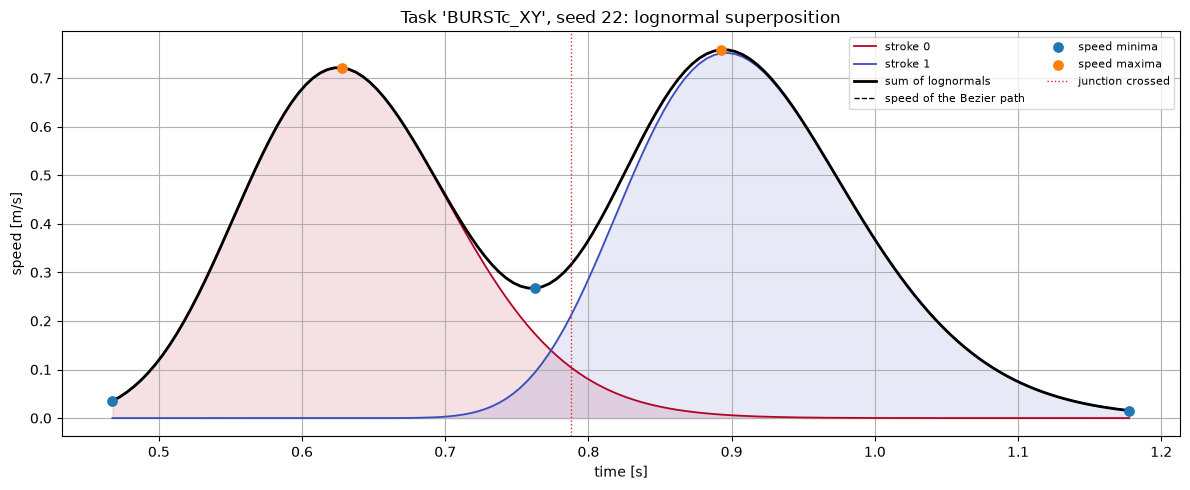

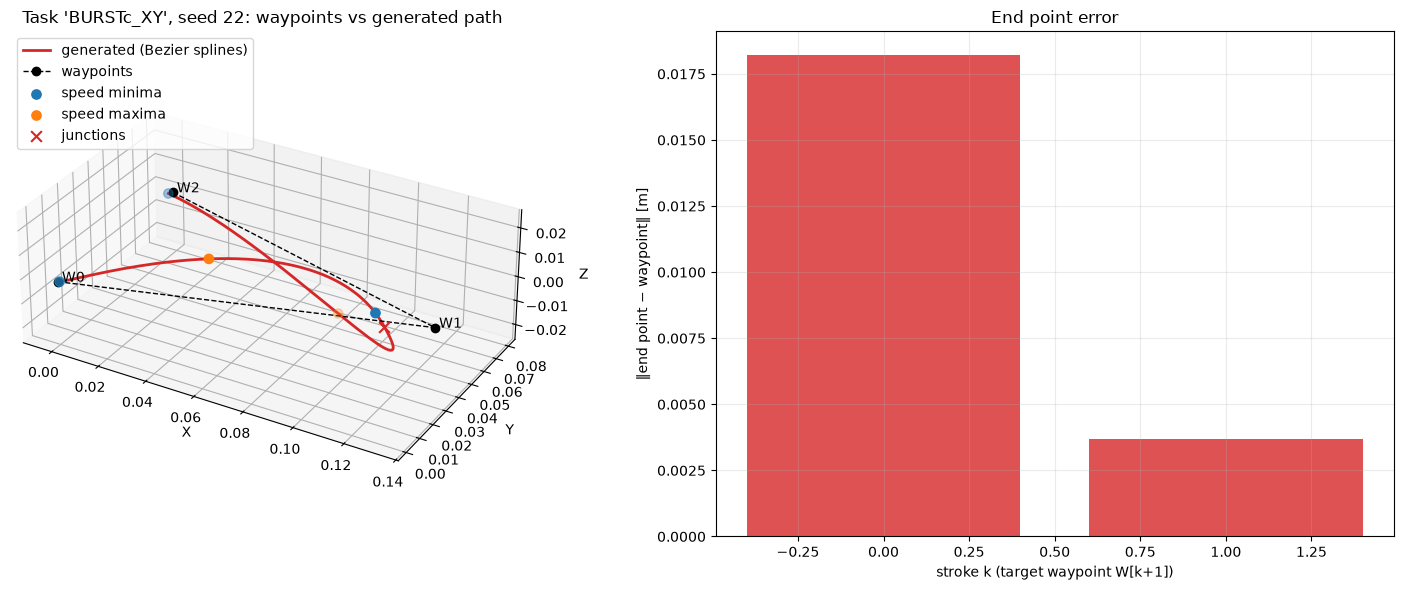

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number      dt0       t0        mu    sigma        D  lambda_s  lambda_e                   u_s                     u_e                    delta_p
             0 0.007660 0.007660  0.103168 0.071381 0.221168  0.024256  0.091832  (0.949, 0.31, 0.058)   (0.529, 0.817, 0.229)   (0.2014, 0.0658, 0.0123)
             1 0.770855 0.778515 -0.650816 0.177979 0.190972  0.075979  0.045594 (0.529, 0.817, 0.229) (-0.812, -0.556, 0.178) (-0.1483, 0.0147, -0.0143)


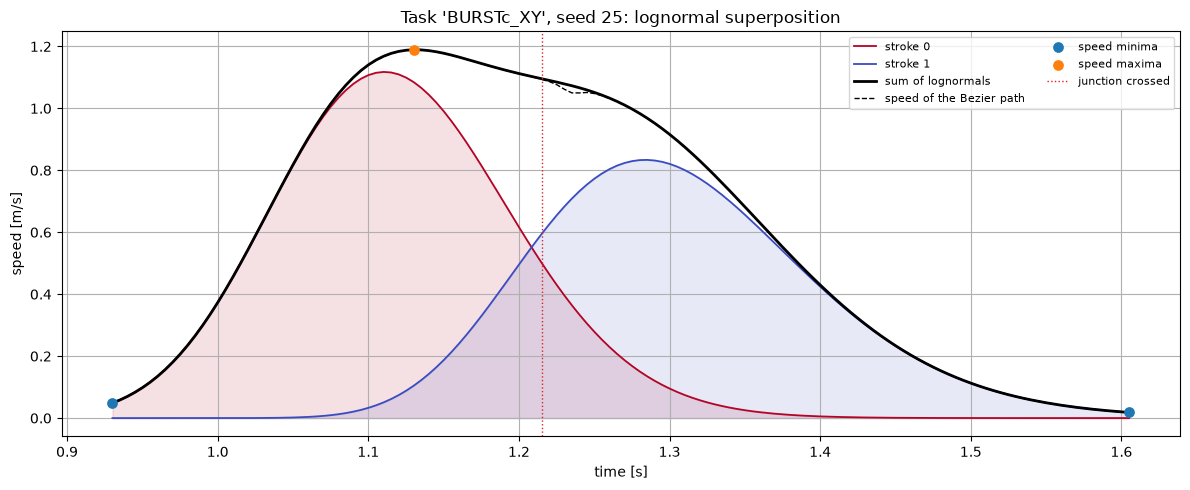

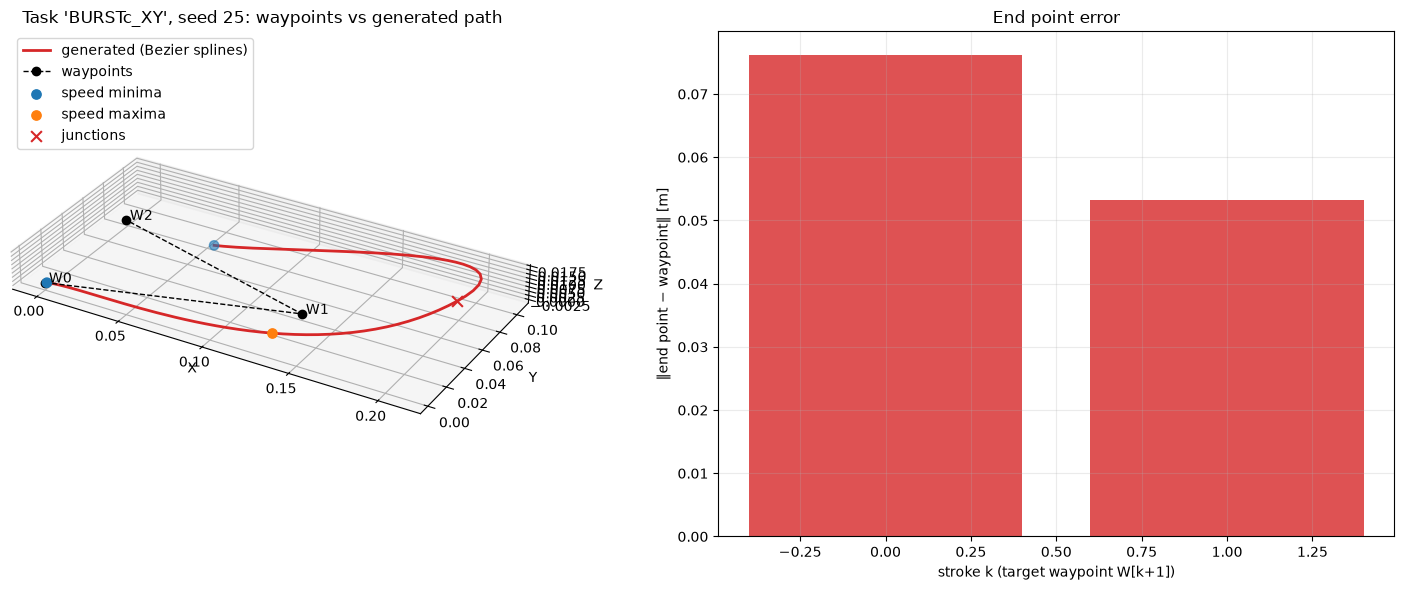

tasks: ['BURSTc_XY', 'BURSTc_XZ', 'BURSTc_YZ', 'BURSTs_XY', 'BURSTs_XZ', 'BURSTs_YZ', 'CHECK_XY', 'CHECK_XZ', 'EACH_AXIS_90', 'HOOK_XY', 'HOOK_YZ', 'LETTER_N', 'LETTER_NABLA', 'LETTER_S', 'LETTER_Z', 'REVERSAL_3D', 'REVERSAL_Z']
 stroke_number      dt0       t0       mu    sigma        D  lambda_s  lambda_e                   u_s                   u_e                    delta_p
             0 0.002979 0.002979 -0.16506 0.096172 0.113780  0.098685  0.012568 (0.966, 0.232, 0.115)  (0.263, 0.96, 0.098)   (0.1079, 0.0259, 0.0129)
             1 0.577753 0.580732 -0.50846 0.176755 0.214012  0.085815  0.048355  (0.263, 0.96, 0.098) (-0.95, -0.308, 0.06) (-0.1736, 0.0338, -0.0111)


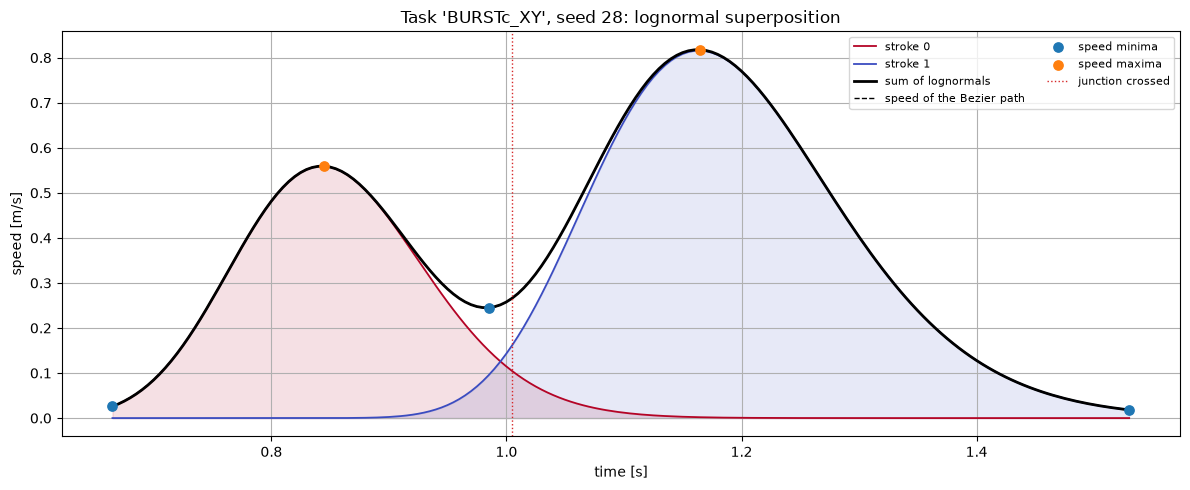

KeyboardInterrupt: 

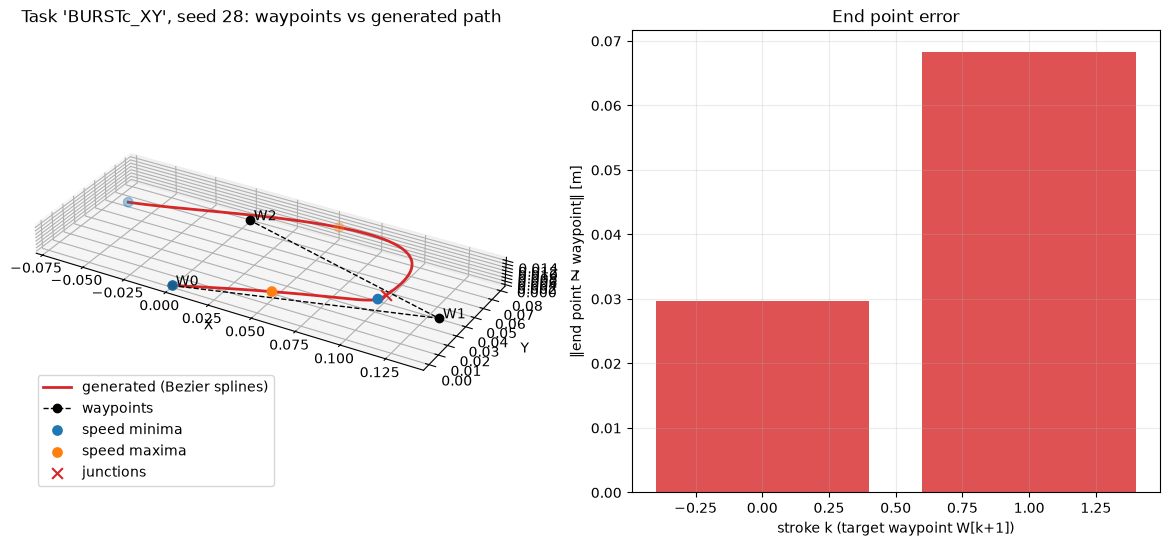

In [ ]:
# model / stats of the best checkpoint: the ones just trained, or reload them from disk
# model, stats, _ = load_checkpoint(CKPT_PATH)
for i in range(10, 15, 1):
  print("tasks:", sorted(WAYPOINTS_BY_TASK))
  TASK = "BURSTc_XY"
  SEED = i
  strokes, result = generate_and_plot(model, stats, TASK, SEED)